In [1]:
import kagglehub

path = kagglehub.dataset_download("apollo2506/eurosat-dataset")

print("Path to dataset files:", path)


Path to dataset files: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6


In [2]:
import os

print("Dataset path:", path)

for item in os.listdir(path):
    print(item)

Dataset path: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6
EuroSAT
EuroSATallBands


In [3]:
import os

rgb_path = os.path.join(path, "EuroSAT")

print("RGB dataset path:", rgb_path)
print("\nContents of EuroSAT:")

for item in os.listdir(rgb_path):
    print(item)

RGB dataset path: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT

Contents of EuroSAT:
AnnualCrop
Forest
HerbaceousVegetation
Highway
Industrial
label_map.json
Pasture
PermanentCrop
Residential
River
SeaLake
test.csv
train.csv
validation.csv


In [4]:
import pandas as pd
import os

train_df = pd.read_csv(os.path.join(rgb_path, "train.csv"))
val_df = pd.read_csv(os.path.join(rgb_path, "validation.csv"))
test_df = pd.read_csv(os.path.join(rgb_path, "test.csv"))

print("Training data:")
print(train_df.head())
print("\nTraining shape:", train_df.shape)

print("\nValidation shape:", val_df.shape)
print("\nTest shape:", test_df.shape)

print("\nTraining columns:", train_df.columns.tolist())

Training data:
   Unnamed: 0                                           Filename  Label  \
0       16257                      AnnualCrop/AnnualCrop_142.jpg      0   
1        3297  HerbaceousVegetation/HerbaceousVegetation_2835...      2   
2       17881               PermanentCrop/PermanentCrop_1073.jpg      6   
3        2223                      Industrial/Industrial_453.jpg      4   
4        4887  HerbaceousVegetation/HerbaceousVegetation_1810...      2   

              ClassName  
0            AnnualCrop  
1  HerbaceousVegetation  
2         PermanentCrop  
3            Industrial  
4  HerbaceousVegetation  

Training shape: (18900, 4)

Validation shape: (5400, 4)

Test shape: (2700, 4)

Training columns: ['Unnamed: 0', 'Filename', 'Label', 'ClassName']


In [5]:

from PIL import Image
import os

first_image_path = os.path.join(
    rgb_path,
    train_df.iloc[0]["Filename"]
)

img = Image.open(first_image_path)

print("Image path:", first_image_path)
print("Image dimensions (width, height):", img.size)
print("Image mode:", img.mode)
print("Image format:", img.format)


Image path: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT\AnnualCrop/AnnualCrop_142.jpg
Image dimensions (width, height): (64, 64)
Image mode: RGB
Image format: JPEG


In [6]:
print("Class mapping from training data:")

print(
    train_df[["Label", "ClassName"]]
    .drop_duplicates()
    .sort_values("Label")
    .to_string(index=False)
)

print("\nNumber of unique classes:", train_df["Label"].nunique())

print("\nTraining samples per class:")
print(train_df["ClassName"].value_counts().sort_index())

Class mapping from training data:
 Label            ClassName
     0           AnnualCrop
     1               Forest
     2 HerbaceousVegetation
     3              Highway
     4           Industrial
     5              Pasture
     6        PermanentCrop
     7          Residential
     8                River
     9              SeaLake

Number of unique classes: 10

Training samples per class:
ClassName
AnnualCrop              2100
Forest                  2100
HerbaceousVegetation    2100
Highway                 1750
Industrial              1750
Pasture                 1400
PermanentCrop           1750
Residential             2100
River                   1750
SeaLake                 2100
Name: count, dtype: int64


In [7]:
import numpy as np
import os
from PIL import Image

def load_eurosat_images(dataframe, image_folder):
    images = np.empty(
        (len(dataframe), 64, 64, 3),
        dtype=np.uint8
    )
    labels = dataframe["Label"].to_numpy(dtype=np.int64)

    for i, filename in enumerate(dataframe["Filename"]):
        image_path = os.path.join(image_folder, filename)

        with Image.open(image_path) as img:
            images[i] = np.asarray(img.convert("RGB"), dtype=np.uint8)

    return images, labels


X_train, y_train = load_eurosat_images(train_df, rgb_path)
X_val, y_val = load_eurosat_images(val_df, rgb_path)
X_test, y_test = load_eurosat_images(test_df, rgb_path)

print("Training images:", X_train.shape)
print("Training labels:", y_train.shape)

print("Validation images:", X_val.shape)
print("Validation labels:", y_val.shape)

print("Test images:", X_test.shape)
print("Test labels:", y_test.shape)

Training images: (18900, 64, 64, 3)
Training labels: (18900,)
Validation images: (5400, 64, 64, 3)
Validation labels: (5400,)
Test images: (2700, 64, 64, 3)
Test labels: (2700,)


In [8]:
# Step 1: Normalize pixel values from 0–255 to 0–1
X_train = X_train.astype(np.float32) / 255.0
X_val = X_val.astype(np.float32) / 255.0
X_test = X_test.astype(np.float32) / 255.0

# Step 2: Flatten each image into 12,288 features
X_train = X_train.reshape(X_train.shape[0], -1)
X_val = X_val.reshape(X_val.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

# Step 3: Check the results
print("Training input:", X_train.shape)
print("Validation input:", X_val.shape)
print("Testing input:", X_test.shape)

print("Minimum pixel value:", X_train.min())
print("Maximum pixel value:", X_train.max())

Training input: (18900, 12288)
Validation input: (5400, 12288)
Testing input: (2700, 12288)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [10]:
%pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/384.1 MB ? eta -:--:--
   ---------------------------------------- 1.8/384.1 MB 15.6 MB/s eta 0:00:25
   - -------------------------------------- 11.0/384.1 MB 34.9 MB/s eta 0:00:11
   - -------------------------------------- 16.3/384.1 MB 31.1 MB/s eta 0:00:12
   -- ------------------------------------- 19.9/384.1 MB 27.3 MB/s eta 0:00:14
   -- ------------------------------------- 23.6/384.1 MB 25.0 MB/s eta 0:00:15
   -- ------------------------------------- 27.3/384.1 MB 23.6 MB/s eta 0:00:16
   --- ------------------------------------ 30.1/384.1 MB 21.9 MB/s eta 0:00:17
   --- ------------------------------------ 32.2/384.1 MB 20.8 MB/s eta 0:00:17
   --- ------------------------------------ 34.3/384.1 MB 19.2 MB/s eta 0:00:19
   --- ------------------------------------ 36.2/384.1 MB 18.2 MB/s eta 0:00:20
   --- ------------------------------------ 37.5/384

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [11]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("Number of classes:", train_df["Label"].nunique())
print("Number of input features:", X_train.shape[1])

TensorFlow version: 2.22.0-rc0
Number of classes: 10
Number of input features: 12288


In [12]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input

model = Sequential([
    Input(shape=(12288,)),

    Dense(64, activation="relu"),
    Dense(64, activation="relu"),

    Dense(10, activation="softmax")
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 64)                  │         786,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 791,306 (3.02 MB)

 Trainable params: 791,306 (3.02 MB)

 Non-trainable params: 0 (0.00 B)

In [13]:
import os

results_dir = os.path.join(
    os.path.expanduser("~"),
    "EuroSAT_ANN_Results"
)

plots_dir = os.path.join(results_dir, "Plots")
tables_dir = os.path.join(results_dir, "Results_Tables")
models_dir = os.path.join(results_dir, "Saved_Models")
histories_dir = os.path.join(results_dir, "Training_Histories")

for folder in [plots_dir, tables_dir, models_dir, histories_dir]:
    os.makedirs(folder, exist_ok=True)

print("Results folder:", results_dir)
print("Plots folder:", plots_dir)
print("Tables folder:", tables_dir)
print("Models folder:", models_dir)
print("Training histories folder:", histories_dir)

Results folder: C:\Users\jaswa\EuroSAT_ANN_Results
Plots folder: C:\Users\jaswa\EuroSAT_ANN_Results\Plots
Tables folder: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables
Models folder: C:\Users\jaswa\EuroSAT_ANN_Results\Saved_Models
Training histories folder: C:\Users\jaswa\EuroSAT_ANN_Results\Training_Histories


In [14]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline ANN compiled successfully.")

Baseline ANN compiled successfully.


In [15]:
from tensorflow.keras.optimizers import Adam

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Baseline ANN compiled successfully.")

Baseline ANN compiled successfully.


In [16]:
import matplotlib.pyplot as plt
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=128,
    callbacks=[early_stop],
    verbose=1
)

print("\nBaseline training completed.")
print("Best validation accuracy:",
      round(max(history.history["val_accuracy"]) * 100, 2), "%")
print("Lowest validation loss:",
      round(min(history.history["val_loss"]), 4))

Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.2591 - loss: 2.0093 - val_accuracy: 0.3370 - val_loss: 1.7539
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.3696 - loss: 1.6838 - val_accuracy: 0.4093 - val_loss: 1.6488
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4138 - loss: 1.5956 - val_accuracy: 0.4365 - val_loss: 1.5632
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4381 - loss: 1.5335 - val_accuracy: 0.4596 - val_loss: 1.5042
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4438 - loss: 1.5063 - val_accuracy: 0.4570 - val_loss: 1.4916
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4613 - loss: 1.4692 - val_accuracy: 0.4657 - val_loss: 1.4756
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4702 - loss: 1.4436 - val_accuracy: 0.4767 - val_loss: 1.4609
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4757 - loss: 1.4247 - val_accuracy: 0

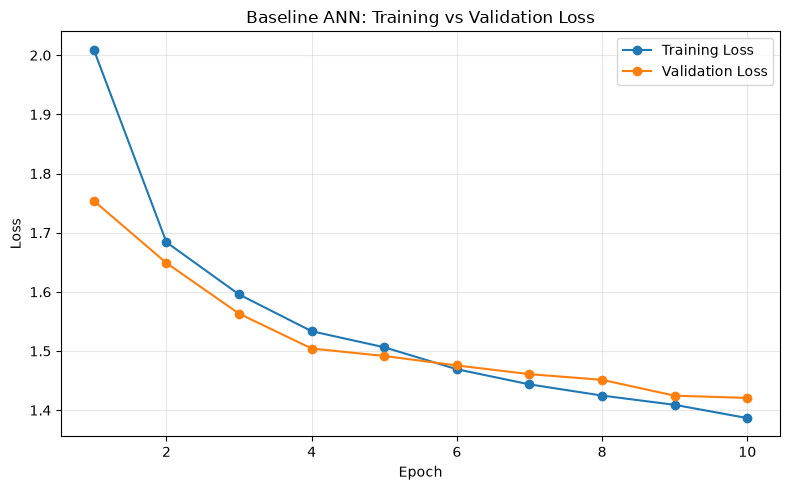

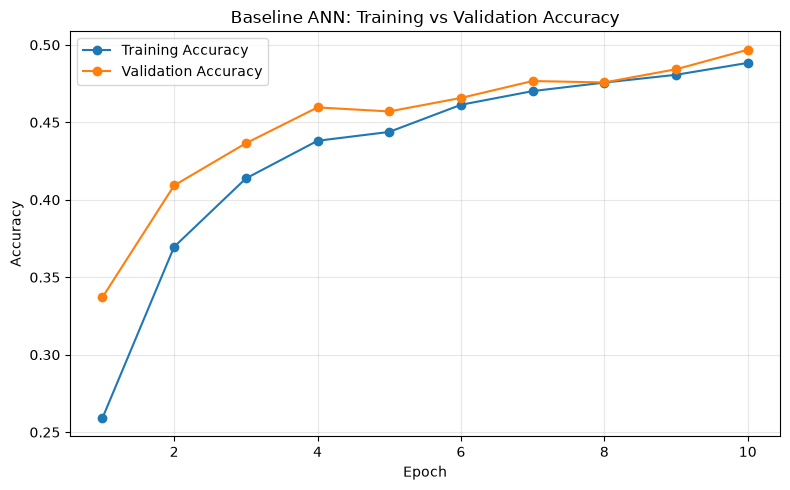

Training history saved to: C:\Users\jaswa\EuroSAT_ANN_Results\Training_Histories\baseline_training_history.csv
Loss and accuracy plots saved to: C:\Users\jaswa\EuroSAT_ANN_Results\Plots

Epoch-wise results:
       accuracy    loss  val_accuracy  val_loss
Epoch                                          
1        0.2591  2.0093        0.3370    1.7539
2        0.3696  1.6838        0.4093    1.6488
3        0.4138  1.5956        0.4365    1.5632
4        0.4381  1.5335        0.4596    1.5042
5        0.4438  1.5063        0.4570    1.4916
6        0.4613  1.4692        0.4657    1.4756
7        0.4702  1.4436        0.4767    1.4609
8        0.4757  1.4247        0.4757    1.4513
9        0.4807  1.4090        0.4843    1.4245
10       0.4884  1.3867        0.4969    1.4207


In [17]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Save the actual training history
history_df = pd.DataFrame(history.history)
history_df.index = history_df.index + 1
history_df.index.name = "Epoch"

history_path = os.path.join(
    histories_dir, "baseline_training_history.csv"
)
history_df.to_csv(history_path)

# Plot 1: Training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history_df.index, history_df["loss"], marker="o",
         label="Training Loss")
plt.plot(history_df.index, history_df["val_loss"], marker="o",
         label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline ANN: Training vs Validation Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "baseline_loss_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

# Plot 2: Training and validation accuracy
plt.figure(figsize=(8, 5))
plt.plot(history_df.index, history_df["accuracy"], marker="o",
         label="Training Accuracy")
plt.plot(history_df.index, history_df["val_accuracy"], marker="o",
         label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Baseline ANN: Training vs Validation Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "baseline_accuracy_curve.png"),
    dpi=300, bbox_inches="tight"
)
plt.show()
plt.close()

print("Training history saved to:", history_path)
print("Loss and accuracy plots saved to:", plots_dir)
print("\nEpoch-wise results:")
print(history_df.round(4))

In [18]:
baseline_model_path = os.path.join(
    models_dir,
    "baseline_2_hidden_layers.keras"
)

model.save(baseline_model_path)

print("Baseline ANN model saved successfully.")
print("Saved model path:", baseline_model_path)

Baseline ANN model saved successfully.
Saved model path: C:\Users\jaswa\EuroSAT_ANN_Results\Saved_Models\baseline_2_hidden_layers.keras



Training ANN with 2 hidden layers...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.2704 - loss: 2.0160 - val_accuracy: 0.2794 - val_loss: 1.7717
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3751 - loss: 1.6681 - val_accuracy: 0.3961 - val_loss: 1.6379
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4119 - loss: 1.5812 - val_accuracy: 0.4104 - val_loss: 1.5581
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4361 - loss: 1.5261 - val_accuracy: 0.4378 - val_loss: 1.5072
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4471 - loss: 1.4969 - val_accuracy: 0.4441 - val_loss: 1.4883
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4548 - loss: 1.4800 - val_accuracy: 0.4702 - val_loss: 1.4604
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4668 - loss: 1.4530 - val_accuracy: 0.4830 - val_loss: 1.4323
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0

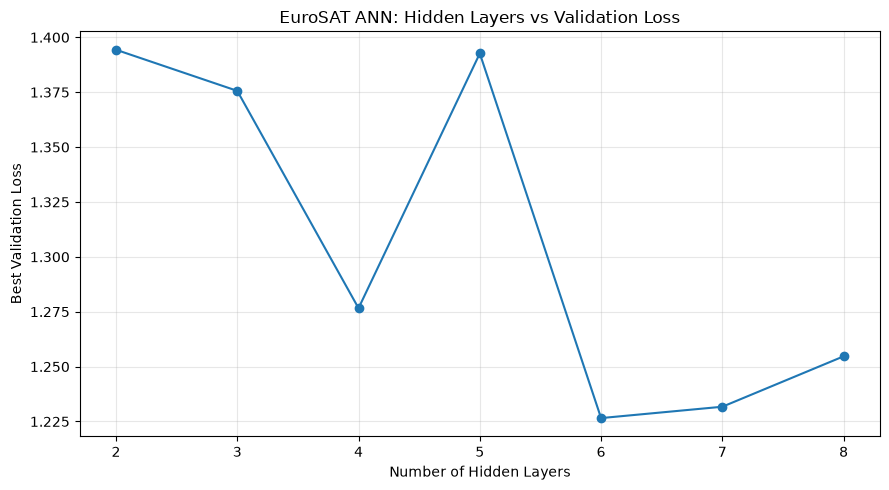

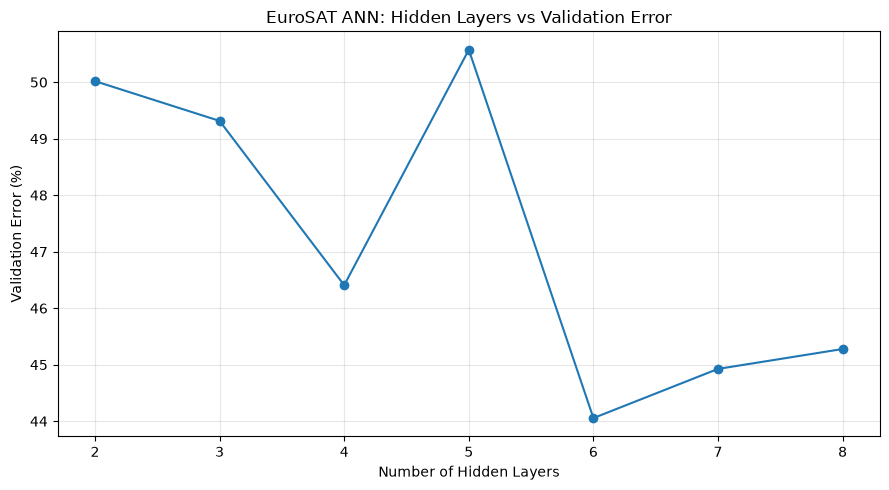


HIDDEN-LAYER EXPERIMENT RESULTS
 Hidden Layers  Neurons Per Layer Activation  Learning Rate  Best Epoch  Validation Loss  Validation Accuracy (%)  Validation Error (%)
             2                 64       ReLU          0.001          10           1.3943                  49.9815               50.0185
             3                 64       ReLU          0.001          10           1.3756                  50.6852               49.3148
             4                 64       ReLU          0.001          10           1.2766                  53.5926               46.4074
             5                 64       ReLU          0.001          10           1.3927                  49.4259               50.5741
             6                 64       ReLU          0.001          10           1.2266                  55.9444               44.0556
             7                 64       ReLU          0.001          10           1.2317                  55.0741               44.9259
             8 

In [19]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

hidden_layer_results = []

for num_layers in range(2, 9):

    print(f"\nTraining ANN with {num_layers} hidden layers...")

    # Build the model
    layers = [Input(shape=(X_train.shape[1],))]

    for _ in range(num_layers):
        layers.append(Dense(64, activation="relu"))

    layers.append(Dense(10, activation="softmax"))

    experiment_model = Sequential(layers)

    # Compile the model
    experiment_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    # Stop when validation loss stops improving
    early_stop_exp = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    # Train the model
    exp_history = experiment_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        callbacks=[early_stop_exp],
        verbose=1
    )

    # Identify the epoch with the lowest validation loss
    best_idx = int(np.argmin(exp_history.history["val_loss"]))

    best_val_loss = exp_history.history["val_loss"][best_idx]
    best_val_accuracy = exp_history.history["val_accuracy"][best_idx]
    best_val_error = (1 - best_val_accuracy) * 100

    # Save model
    model_name = f"ann_{num_layers}_hidden_layers.keras"
    experiment_model.save(os.path.join(models_dir, model_name))

    # Save training history
    history_df = pd.DataFrame(exp_history.history)
    history_df.index = history_df.index + 1
    history_df.index.name = "Epoch"

    history_df.to_csv(
        os.path.join(
            histories_dir,
            f"ann_{num_layers}_hidden_layers_history.csv"
        )
    )

    # Save loss curve
    plt.figure(figsize=(8, 5))
    plt.plot(history_df.index, history_df["loss"],
             marker="o", label="Training Loss")
    plt.plot(history_df.index, history_df["val_loss"],
             marker="o", label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"ANN with {num_layers} Hidden Layers: Loss Curve")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(
            plots_dir,
            f"ann_{num_layers}_hidden_layers_loss.png"
        ),
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    # Record measured results
    hidden_layer_results.append({
        "Hidden Layers": num_layers,
        "Neurons Per Layer": 64,
        "Activation": "ReLU",
        "Learning Rate": 0.001,
        "Best Epoch": best_idx + 1,
        "Validation Loss": best_val_loss,
        "Validation Accuracy (%)": best_val_accuracy * 100,
        "Validation Error (%)": best_val_error
    })

    print(
        f"Best validation loss: {best_val_loss:.4f} | "
        f"Validation error: {best_val_error:.2f}%"
    )

# Create and save the results table
hidden_layer_df = pd.DataFrame(hidden_layer_results)

hidden_layer_df.to_csv(
    os.path.join(
        tables_dir,
        "hidden_layer_comparison.csv"
    ),
    index=False
)

# Plot validation loss comparison
plt.figure(figsize=(9, 5))
plt.plot(
    hidden_layer_df["Hidden Layers"],
    hidden_layer_df["Validation Loss"],
    marker="o"
)
plt.xticks(range(2, 9))
plt.xlabel("Number of Hidden Layers")
plt.ylabel("Best Validation Loss")
plt.title("EuroSAT ANN: Hidden Layers vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "hidden_layer_validation_loss_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Plot validation error comparison
plt.figure(figsize=(9, 5))
plt.plot(
    hidden_layer_df["Hidden Layers"],
    hidden_layer_df["Validation Error (%)"],
    marker="o"
)
plt.xticks(range(2, 9))
plt.xlabel("Number of Hidden Layers")
plt.ylabel("Validation Error (%)")
plt.title("EuroSAT ANN: Hidden Layers vs Validation Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "hidden_layer_validation_error_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nHIDDEN-LAYER EXPERIMENT RESULTS")
print(hidden_layer_df.round(4).to_string(index=False))
print("\nResults saved in:", results_dir)


Training model with relu activation...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.2188 - loss: 2.0577 - val_accuracy: 0.2676 - val_loss: 1.8303
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2868 - loss: 1.7586 - val_accuracy: 0.2880 - val_loss: 1.7655
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3246 - loss: 1.7227 - val_accuracy: 0.3498 - val_loss: 1.7237
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3566 - loss: 1.6939 - val_accuracy: 0.3480 - val_loss: 1.6866
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3689 - loss: 1.6677 - val_accuracy: 0.3543 - val_loss: 1.6580
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3801 - loss: 1.6444 - val_accuracy: 0.3669 - val_loss: 1.6350
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3883 - loss: 1.6257 - val_accuracy: 0.3791 - val_loss: 1.6146
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy:

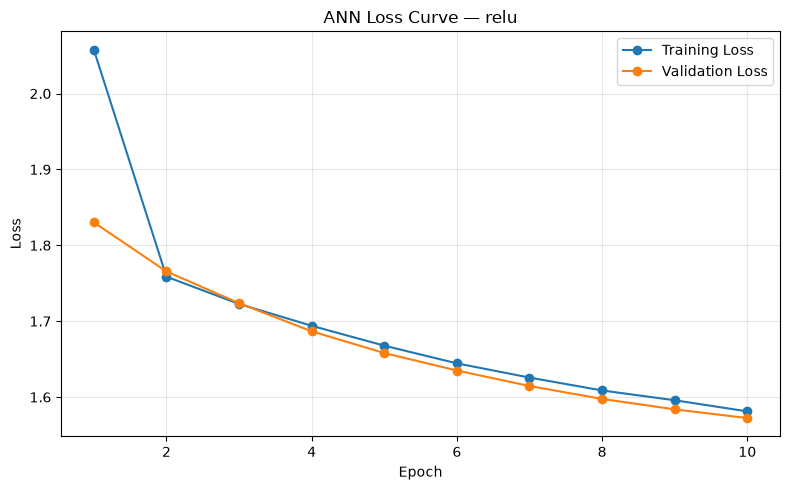


Training model with tanh activation...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.1048 - loss: 2.3815 - val_accuracy: 0.1111 - val_loss: 2.3000
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1086 - loss: 2.3018 - val_accuracy: 0.1111 - val_loss: 2.3000
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1070 - loss: 2.3018 - val_accuracy: 0.1111 - val_loss: 2.3001
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1066 - loss: 2.3016 - val_accuracy: 0.1111 - val_loss: 2.3001
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1070 - loss: 2.3013 - val_accuracy: 0.0926 - val_loss: 2.3002


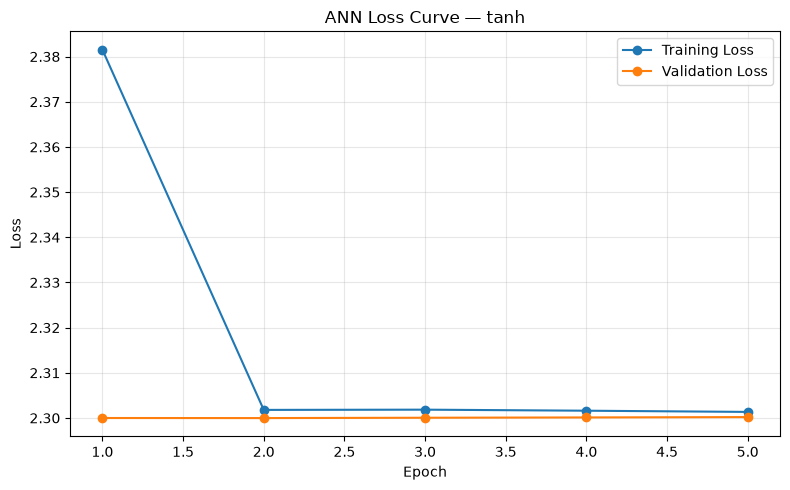


Training model with sigmoid activation...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1999 - loss: 2.1858 - val_accuracy: 0.2019 - val_loss: 2.0443
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2352 - loss: 1.9392 - val_accuracy: 0.2322 - val_loss: 1.8809
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2517 - loss: 1.8492 - val_accuracy: 0.2335 - val_loss: 1.8408
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2615 - loss: 1.8094 - val_accuracy: 0.2446 - val_loss: 1.7991
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2695 - loss: 1.7811 - val_accuracy: 0.2754 - val_loss: 1.7766
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2778 - loss: 1.7628 - val_accuracy: 0.2669 - val_loss: 1.7840
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2902 - loss: 1.7497 - val_accuracy: 0.2752 - val_loss: 1.7618
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accura

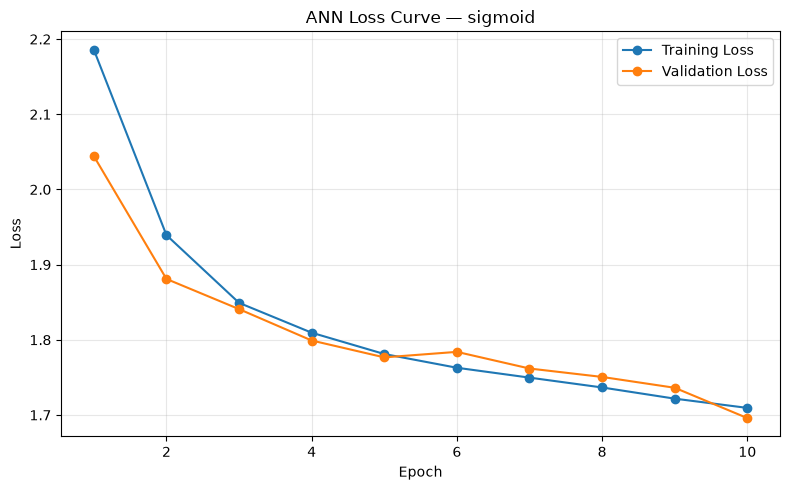

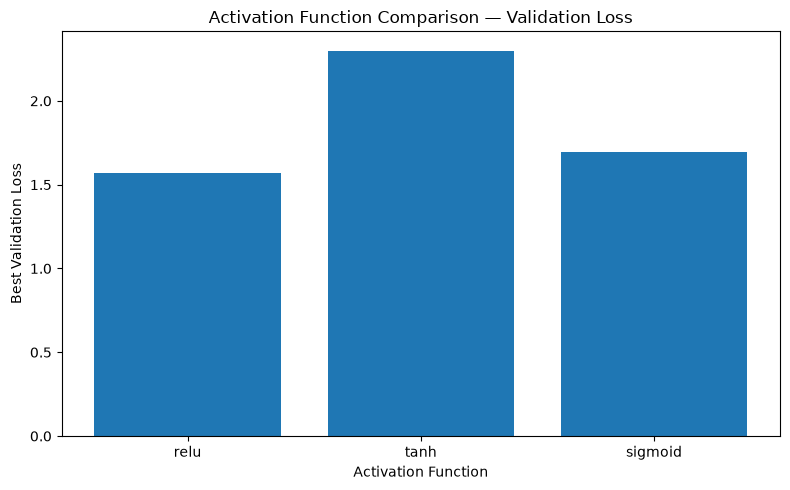

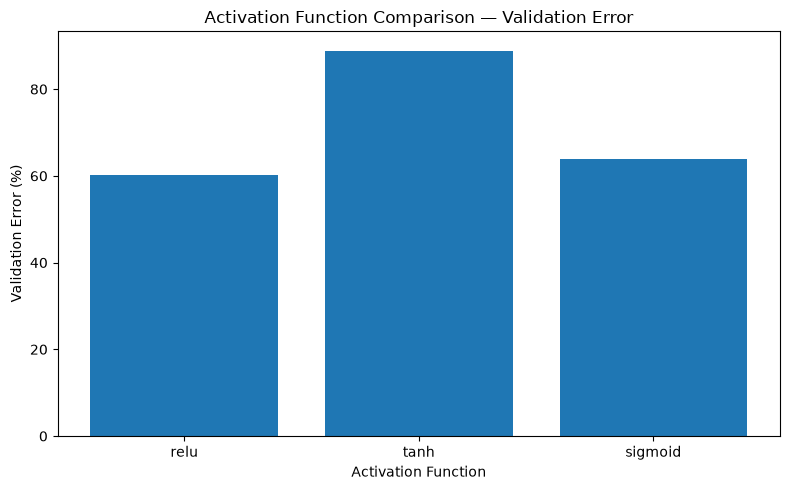


ACTIVATION FUNCTION RESULTS
Activation  Best Epoch  Validation Loss  Validation Accuracy (%)  Validation Error (%)
      relu          10           1.5723                  39.8889               60.1111
      tanh           2           2.3000                  11.1111               88.8889
   sigmoid          10           1.6959                  36.1667               63.8333

Results saved in: C:\Users\jaswa\EuroSAT_ANN_Results


In [20]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

activation_results = []

for activation_name in ["relu", "tanh", "sigmoid"]:

    print(f"\nTraining model with {activation_name} activation...")

    activation_model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation=activation_name),
        Dense(64, activation=activation_name),
        Dense(10, activation="softmax")
    ])

    activation_model.compile(
        optimizer=Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop_activation = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    activation_history = activation_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        callbacks=[early_stop_activation],
        verbose=1
    )

    best_idx = int(np.argmin(activation_history.history["val_loss"]))

    best_val_loss = activation_history.history["val_loss"][best_idx]
    best_val_accuracy = activation_history.history["val_accuracy"][best_idx]

    # Save the trained model
    activation_model.save(
        os.path.join(
            models_dir,
            f"activation_{activation_name}.keras"
        )
    )

    # Save epoch-wise training history
    activation_history_df = pd.DataFrame(activation_history.history)
    activation_history_df.index = activation_history_df.index + 1
    activation_history_df.index.name = "Epoch"

    activation_history_df.to_csv(
        os.path.join(
            histories_dir,
            f"activation_{activation_name}_history.csv"
        )
    )

    # Save training and validation loss curve
    plt.figure(figsize=(8, 5))
    plt.plot(
        activation_history_df.index,
        activation_history_df["loss"],
        marker="o",
        label="Training Loss"
    )
    plt.plot(
        activation_history_df.index,
        activation_history_df["val_loss"],
        marker="o",
        label="Validation Loss"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"ANN Loss Curve — {activation_name}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(plots_dir, f"activation_{activation_name}_loss.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    activation_results.append({
        "Activation": activation_name,
        "Best Epoch": best_idx + 1,
        "Validation Loss": best_val_loss,
        "Validation Accuracy (%)": best_val_accuracy * 100,
        "Validation Error (%)": (1 - best_val_accuracy) * 100
    })

# Save comparison table
activation_df = pd.DataFrame(activation_results)

activation_df.to_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv"),
    index=False
)

# Compare validation loss
plt.figure(figsize=(8, 5))
plt.bar(activation_df["Activation"], activation_df["Validation Loss"])
plt.xlabel("Activation Function")
plt.ylabel("Best Validation Loss")
plt.title("Activation Function Comparison — Validation Loss")
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "activation_validation_loss_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Compare validation error
plt.figure(figsize=(8, 5))
plt.bar(
    activation_df["Activation"],
    activation_df["Validation Error (%)"]
)
plt.xlabel("Activation Function")
plt.ylabel("Validation Error (%)")
plt.title("Activation Function Comparison — Validation Error")
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "activation_validation_error_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nACTIVATION FUNCTION RESULTS")
print(activation_df.round(4).to_string(index=False))
print("\nResults saved in:", results_dir)


Training model with learning rate = 0.1...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.1076 - loss: 30.2015 - val_accuracy: 0.1111 - val_loss: 2.2967
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.1100 - loss: 2.2977 - val_accuracy: 0.1111 - val_loss: 2.2979
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1108 - loss: 2.2986 - val_accuracy: 0.1111 - val_loss: 2.2988
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1123 - loss: 2.2993 - val_accuracy: 0.1111 - val_loss: 2.2995


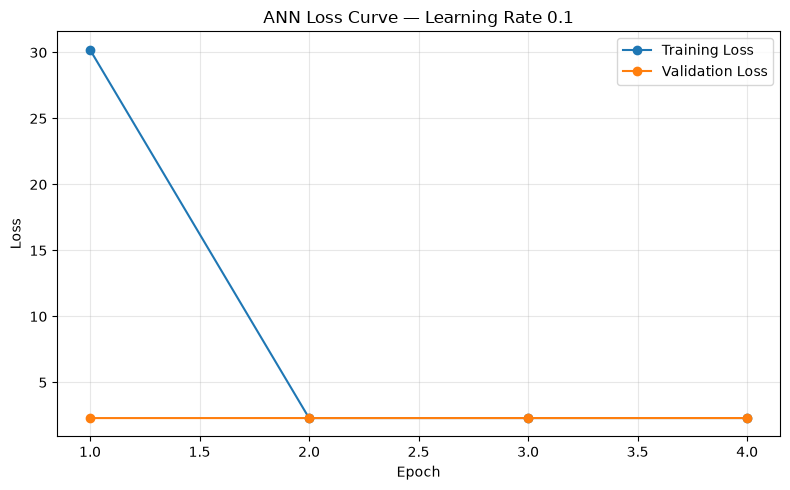


Training model with learning rate = 0.01...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.1063 - loss: 4.2111 - val_accuracy: 0.1111 - val_loss: 2.2950
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1076 - loss: 2.2953 - val_accuracy: 0.1111 - val_loss: 2.2950
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1057 - loss: 2.2956 - val_accuracy: 0.1111 - val_loss: 2.2951
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.1051 - loss: 2.2956 - val_accuracy: 0.1111 - val_loss: 2.2950


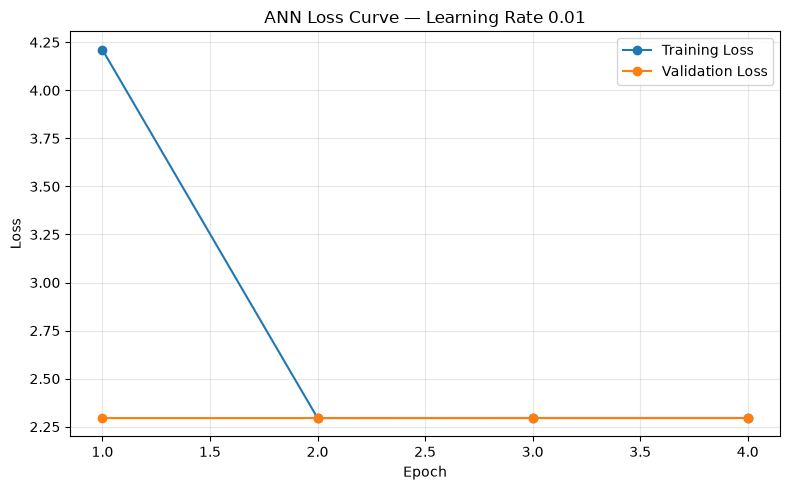


Training model with learning rate = 0.001...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 3s 13ms/step - accuracy: 0.2687 - loss: 1.9786 - val_accuracy: 0.3391 - val_loss: 1.7551
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3851 - loss: 1.6634 - val_accuracy: 0.4070 - val_loss: 1.6392
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4172 - loss: 1.5826 - val_accuracy: 0.4043 - val_loss: 1.5983
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4363 - loss: 1.5255 - val_accuracy: 0.4294 - val_loss: 1.5330
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4543 - loss: 1.4852 - val_accuracy: 0.4565 - val_loss: 1.4977
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4602 - loss: 1.4641 - val_accuracy: 0.4659 - val_loss: 1.4678
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4684 - loss: 1.4443 - val_accuracy: 0.4741 - val_loss: 1.4471
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - acc

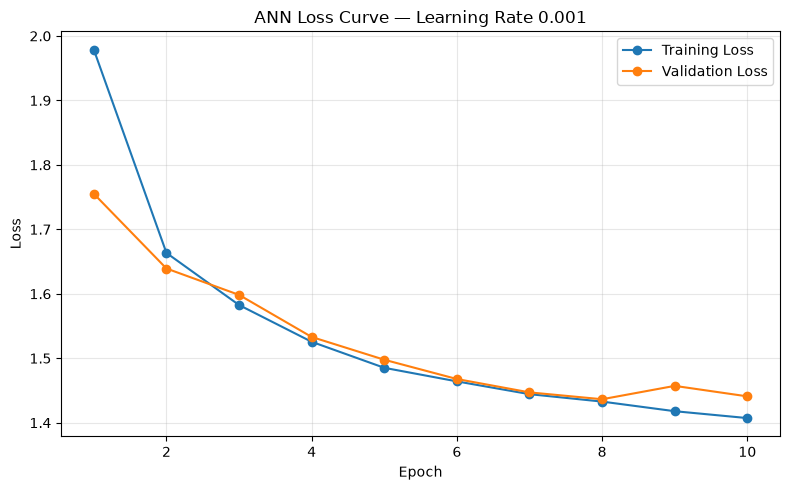


Training model with learning rate = 0.0001...
Epoch 1/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.2474 - loss: 2.0565 - val_accuracy: 0.2926 - val_loss: 1.8564
Epoch 2/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3515 - loss: 1.7737 - val_accuracy: 0.3643 - val_loss: 1.7230
Epoch 3/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.3952 - loss: 1.6862 - val_accuracy: 0.3989 - val_loss: 1.6625
Epoch 4/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4153 - loss: 1.6407 - val_accuracy: 0.4148 - val_loss: 1.6270
Epoch 5/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4256 - loss: 1.6097 - val_accuracy: 0.4276 - val_loss: 1.6023
Epoch 6/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4354 - loss: 1.5853 - val_accuracy: 0.4296 - val_loss: 1.5825
Epoch 7/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.4412 - loss: 1.5658 - val_accuracy: 0.4307 - val_loss: 1.5655
Epoch 8/10
148/148 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - ac

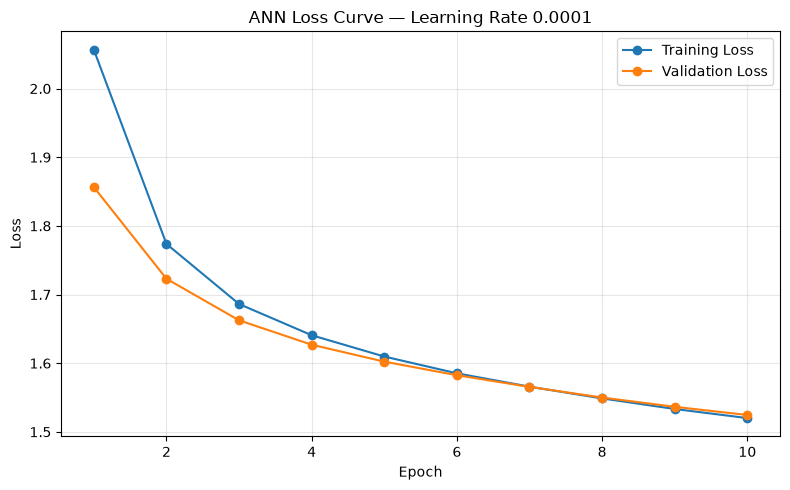

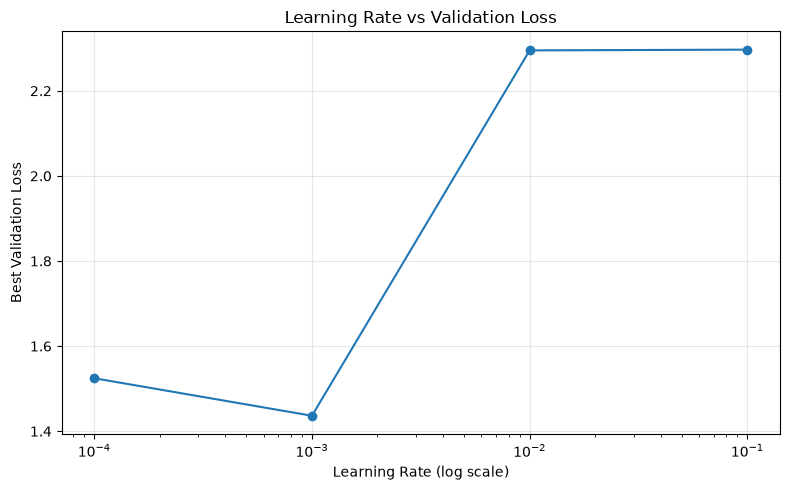

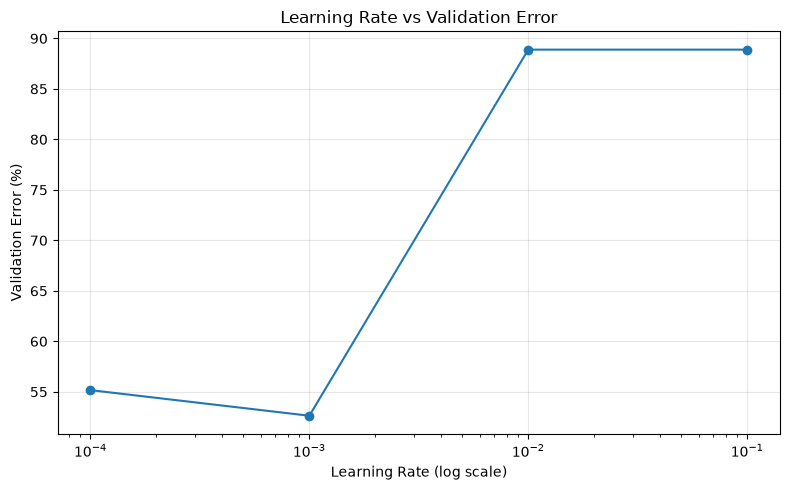


LEARNING RATE RESULTS
 Learning Rate  Best Epoch  Validation Loss  Validation Accuracy (%)  Validation Error (%)
        0.1000           1           2.2967                  11.1111               88.8889
        0.0100           1           2.2950                  11.1111               88.8889
        0.0010           8           1.4364                  47.3704               52.6296
        0.0001          10           1.5246                  44.8333               55.1667

Results saved in: C:\Users\jaswa\EuroSAT_ANN_Results


In [21]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

learning_rates = [0.1, 0.01, 0.001, 0.0001]
learning_rate_results = []

for lr in learning_rates:

    print(f"\nTraining model with learning rate = {lr}...")

    lr_model = Sequential([
        Input(shape=(X_train.shape[1],)),
        Dense(64, activation="relu"),
        Dense(64, activation="relu"),
        Dense(10, activation="softmax")
    ])

    lr_model.compile(
        optimizer=Adam(learning_rate=lr),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    early_stop_lr = EarlyStopping(
        monitor="val_loss",
        patience=3,
        restore_best_weights=True
    )

    lr_history = lr_model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=10,
        batch_size=128,
        callbacks=[early_stop_lr],
        verbose=1
    )

    best_idx = int(np.argmin(lr_history.history["val_loss"]))
    best_val_loss = lr_history.history["val_loss"][best_idx]
    best_val_accuracy = lr_history.history["val_accuracy"][best_idx]

    # Create a filename-friendly learning-rate label
    lr_label = str(lr).replace(".", "p")

    # Save model
    lr_model.save(
        os.path.join(models_dir, f"learning_rate_{lr_label}.keras")
    )

    # Save epoch-wise history
    lr_history_df = pd.DataFrame(lr_history.history)
    lr_history_df.index = lr_history_df.index + 1
    lr_history_df.index.name = "Epoch"

    lr_history_df.to_csv(
        os.path.join(
            histories_dir,
            f"learning_rate_{lr_label}_history.csv"
        )
    )

    # Save individual loss curve
    plt.figure(figsize=(8, 5))
    plt.plot(
        lr_history_df.index, lr_history_df["loss"],
        marker="o", label="Training Loss"
    )
    plt.plot(
        lr_history_df.index, lr_history_df["val_loss"],
        marker="o", label="Validation Loss"
    )
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"ANN Loss Curve — Learning Rate {lr}")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.savefig(
        os.path.join(plots_dir, f"learning_rate_{lr_label}_loss.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

    learning_rate_results.append({
        "Learning Rate": lr,
        "Best Epoch": best_idx + 1,
        "Validation Loss": best_val_loss,
        "Validation Accuracy (%)": best_val_accuracy * 100,
        "Validation Error (%)": (1 - best_val_accuracy) * 100
    })

# Save results table
learning_rate_df = pd.DataFrame(learning_rate_results)
learning_rate_df.to_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv"),
    index=False
)

# Plot validation loss comparison
plt.figure(figsize=(8, 5))
plt.plot(
    learning_rate_df["Learning Rate"],
    learning_rate_df["Validation Loss"],
    marker="o"
)
plt.xscale("log")
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Best Validation Loss")
plt.title("Learning Rate vs Validation Loss")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "learning_rate_validation_loss_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

# Plot validation error comparison
plt.figure(figsize=(8, 5))
plt.plot(
    learning_rate_df["Learning Rate"],
    learning_rate_df["Validation Error (%)"],
    marker="o"
)
plt.xscale("log")
plt.xlabel("Learning Rate (log scale)")
plt.ylabel("Validation Error (%)")
plt.title("Learning Rate vs Validation Error")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(
    os.path.join(plots_dir, "learning_rate_validation_error_comparison.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()
plt.close()

print("\nLEARNING RATE RESULTS")
print(learning_rate_df.round(4).to_string(index=False))
print("\nResults saved in:", results_dir)

In [22]:
import os
import numpy as np
import pandas as pd

# Collect results from all experiments
all_results = []

# 1. Baseline model
baseline_history = pd.read_csv(
    os.path.join(histories_dir, "baseline_training_history.csv"),
    index_col=0
)

baseline_best_epoch = baseline_history["val_loss"].idxmin()
baseline_best = baseline_history.loc[baseline_best_epoch]

all_results.append({
    "Experiment": "Baseline",
    "Configuration": "2 layers, ReLU, LR=0.001",
    "Best Epoch": int(baseline_best_epoch),
    "Validation Loss": baseline_best["val_loss"],
    "Validation Accuracy (%)": baseline_best["val_accuracy"] * 100,
    "Validation Error (%)": (1 - baseline_best["val_accuracy"]) * 100,
    "Model File": "baseline_2_hidden_layers.keras"
})

# 2. Hidden-layer experiment
hidden_df = pd.read_csv(
    os.path.join(tables_dir, "hidden_layer_comparison.csv")
)

for _, row in hidden_df.iterrows():
    n = int(row["Hidden Layers"])

    all_results.append({
        "Experiment": "Hidden Layers",
        "Configuration": f"{n} layers, ReLU, LR=0.001",
        "Best Epoch": int(row["Best Epoch"]),
        "Validation Loss": row["Validation Loss"],
        "Validation Accuracy (%)": row["Validation Accuracy (%)"],
        "Validation Error (%)": row["Validation Error (%)"],
        "Model File": f"ann_{n}_hidden_layers.keras"
    })

# 3. Activation-function experiment
activation_df = pd.read_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv")
)

for _, row in activation_df.iterrows():
    activation = row["Activation"]

    all_results.append({
        "Experiment": "Activation Function",
        "Configuration": f"2 layers, {activation}, LR=0.001",
        "Best Epoch": int(row["Best Epoch"]),
        "Validation Loss": row["Validation Loss"],
        "Validation Accuracy (%)": row["Validation Accuracy (%)"],
        "Validation Error (%)": row["Validation Error (%)"],
        "Model File": f"activation_{activation}.keras"
    })

# 4. Learning-rate experiment
lr_df = pd.read_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv")
)

for _, row in lr_df.iterrows():
    lr = float(row["Learning Rate"])
    lr_label = str(lr).replace(".", "p")

    all_results.append({
        "Experiment": "Learning Rate",
        "Configuration": f"2 layers, ReLU, LR={lr}",
        "Best Epoch": int(row["Best Epoch"]),
        "Validation Loss": row["Validation Loss"],
        "Validation Accuracy (%)": row["Validation Accuracy (%)"],
        "Validation Error (%)": row["Validation Error (%)"],
        "Model File": f"learning_rate_{lr_label}.keras"
    })

# Create the consolidated table
comparison_df = pd.DataFrame(all_results)

comparison_path = os.path.join(
    tables_dir,
    "all_experiments_validation_comparison.csv"
)
comparison_df.to_csv(comparison_path, index=False)

# Exclude invalid loss values before selecting the best model
valid_results = comparison_df[
    np.isfinite(comparison_df["Validation Loss"])
].copy()

if valid_results.empty:
    raise ValueError(
        "No finite validation-loss values found. "
        "Check the individual experiment results."
    )

valid_results = valid_results.sort_values("Validation Loss")
best_result = valid_results.iloc[0]

# Verify that the selected model file exists
best_model_path = os.path.join(
    models_dir, best_result["Model File"]
)

if not os.path.exists(best_model_path):
    raise FileNotFoundError(
        f"Selected model was not found: {best_model_path}"
    )

print("ALL EXPERIMENT RESULTS — RANKED BY VALIDATION LOSS")
print(
    valid_results[
        [
            "Experiment",
            "Configuration",
            "Validation Loss",
            "Validation Accuracy (%)",
            "Validation Error (%)"
        ]
    ].round(4).to_string(index=False)
)

print("\nBEST MODEL SELECTED USING VALIDATION DATA")
print("Configuration:", best_result["Configuration"])
print("Validation loss:", round(best_result["Validation Loss"], 4))
print(
    "Validation accuracy:",
    round(best_result["Validation Accuracy (%)"], 2), "%"
)
print(
    "Validation error:",
    round(best_result["Validation Error (%)"], 2), "%"
)
print("Model path:", best_model_path)
print("\nConsolidated table saved to:", comparison_path)

ALL EXPERIMENT RESULTS — RANKED BY VALIDATION LOSS
         Experiment               Configuration  Validation Loss  Validation Accuracy (%)  Validation Error (%)
      Hidden Layers    6 layers, ReLU, LR=0.001           1.2266                  55.9444               44.0556
      Hidden Layers    7 layers, ReLU, LR=0.001           1.2317                  55.0741               44.9259
      Hidden Layers    8 layers, ReLU, LR=0.001           1.2547                  54.7222               45.2778
      Hidden Layers    4 layers, ReLU, LR=0.001           1.2766                  53.5926               46.4074
      Hidden Layers    3 layers, ReLU, LR=0.001           1.3756                  50.6852               49.3148
      Hidden Layers    5 layers, ReLU, LR=0.001           1.3927                  49.4259               50.5741
      Hidden Layers    2 layers, ReLU, LR=0.001           1.3943                  49.9815               50.0185
           Baseline    2 layers, ReLU, LR=0.001      

85/85 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.5519 - loss: 1.2295

FINAL TEST RESULTS
Test Loss: 1.2295
Test Accuracy: 55.19%
Test Error: 44.81%
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step

CLASSIFICATION REPORT
                      precision    recall  f1-score   support

          AnnualCrop       0.52      0.58      0.55       300
              Forest       0.61      0.94      0.74       300
HerbaceousVegetation       0.43      0.59      0.50       300
             Highway       0.25      0.24      0.25       250
          Industrial       0.87      0.68      0.76       250
             Pasture       0.63      0.55      0.58       200
       PermanentCrop       0.57      0.30      0.39       250
         Residential       0.45      0.61      0.52       300
               River       0.54      0.28      0.37       250
             SeaLake       0.87      0.64      0.74       300

            accuracy                           0.55      2700
           macro avg       0.57      0.5

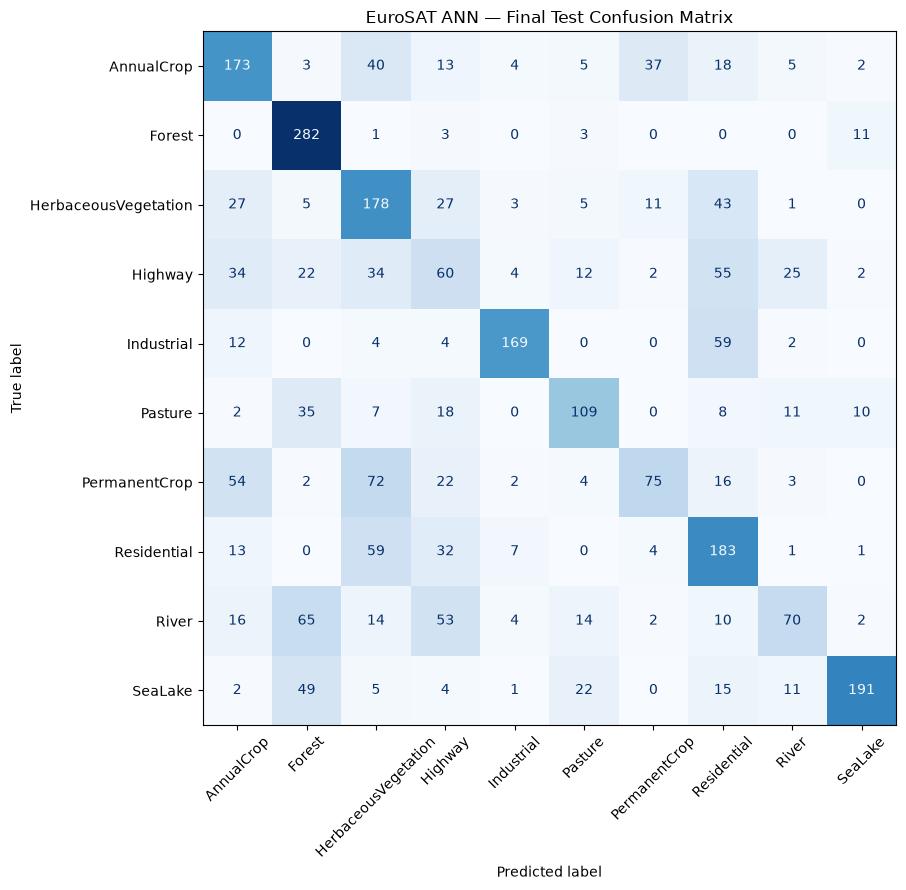


Saved files:
Test metrics: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables\final_test_metrics.csv
Classification report: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables\final_test_classification_report.csv
Confusion matrix CSV: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables\final_test_confusion_matrix.csv
Confusion matrix plot: C:\Users\jaswa\EuroSAT_ANN_Results\Plots\final_test_confusion_matrix.png

All results are in: C:\Users\jaswa\EuroSAT_ANN_Results


In [23]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import load_model
from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

# 1. Load the model selected using validation results
best_model = load_model(best_model_path)

# 2. Evaluate on the held-out test dataset
test_loss, test_accuracy = best_model.evaluate(
    X_test, y_test,
    verbose=1
)

test_error = (1 - test_accuracy) * 100

print("\nFINAL TEST RESULTS")
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Error: {test_error:.2f}%")

# 3. Generate predictions
y_prob = best_model.predict(X_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_prob, axis=1)

# 4. Get class names in label order
class_names = (
    train_df[["Label", "ClassName"]]
    .drop_duplicates()
    .sort_values("Label")["ClassName"]
    .tolist()
)

# 5. Classification report
report_dict = classification_report(
    y_test,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()
report_path = os.path.join(
    tables_dir, "final_test_classification_report.csv"
)
report_df.to_csv(report_path)

print("\nCLASSIFICATION REPORT")
print(
    classification_report(
        y_test,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# 6. Save confusion matrix as CSV
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)
cm_df.index.name = "Actual Class"
cm_df.columns.name = "Predicted Class"

cm_csv_path = os.path.join(
    tables_dir, "final_test_confusion_matrix.csv"
)
cm_df.to_csv(cm_csv_path)

# 7. Plot and save confusion matrix
fig, ax = plt.subplots(figsize=(11, 9))

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

ax.set_title("EuroSAT ANN — Final Test Confusion Matrix")
plt.tight_layout()

cm_plot_path = os.path.join(
    plots_dir, "final_test_confusion_matrix.png"
)
plt.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close()

# 8. Save final test metrics
test_summary = pd.DataFrame([{
    "Selected Configuration": best_result["Configuration"],
    "Test Loss": test_loss,
    "Test Accuracy (%)": test_accuracy * 100,
    "Test Error (%)": test_error,
    "Number of Test Images": len(y_test)
}])

summary_path = os.path.join(
    tables_dir, "final_test_metrics.csv"
)
test_summary.to_csv(summary_path, index=False)

print("\nSaved files:")
print("Test metrics:", summary_path)
print("Classification report:", report_path)
print("Confusion matrix CSV:", cm_csv_path)
print("Confusion matrix plot:", cm_plot_path)
print("\nAll results are in:", results_dir)


In [25]:
import os

print("Results folder:", results_dir)
print("Tables folder:", tables_dir)
print("\nFiles currently in Results_Tables:")

if os.path.exists(tables_dir):
    for file in os.listdir(tables_dir):
        print(file)
else:
    print("Results_Tables folder does not exist.")

Results folder: C:\Users\jaswa\EuroSAT_ANN_Results
Tables folder: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables

Files currently in Results_Tables:
Results_Tables folder does not exist.


In [29]:
print("Hidden-layer results available:", "hidden_layer_df" in globals())
print("Activation results available:", "activation_df" in globals())
print("Learning-rate results available:", "learning_rate_df" in globals())
print("Baseline history available:", "history" in globals())
print("Test summary available:", "test_summary" in globals())

Hidden-layer results available: True
Activation results available: True
Learning-rate results available: True
Baseline history available: True
Test summary available: True


In [30]:
import os
import pandas as pd

# Recreate output folders
results_dir = os.path.join(
    os.path.expanduser("~"), "EuroSAT_ANN_Results"
)
plots_dir = os.path.join(results_dir, "Plots")
tables_dir = os.path.join(results_dir, "Results_Tables")
models_dir = os.path.join(results_dir, "Saved_Models")
histories_dir = os.path.join(results_dir, "Training_Histories")

for folder in [results_dir, plots_dir, tables_dir, models_dir, histories_dir]:
    os.makedirs(folder, exist_ok=True)

# Save the existing experiment results
hidden_layer_df.to_csv(
    os.path.join(tables_dir, "hidden_layer_comparison.csv"),
    index=False
)

activation_df.to_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv"),
    index=False
)

learning_rate_df.to_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv"),
    index=False
)

print("Output folders recreated.")
print("Experiment tables saved.")
print("\nHidden-layer results:", hidden_layer_df.shape)
print("Activation results:", activation_df.shape)
print("Learning-rate results:", learning_rate_df.shape)
print("\nResults folder:", results_dir)

Output folders recreated.
Experiment tables saved.

Hidden-layer results: (7, 8)
Activation results: (3, 5)
Learning-rate results: (4, 5)

Results folder: C:\Users\jaswa\EuroSAT_ANN_Results


In [33]:
from IPython.display import display as show_table

print("HIDDEN-LAYER RESULTS")
print(hidden_layer_df.columns.tolist())
show_table(hidden_layer_df.head(2))

print("\nACTIVATION-FUNCTION RESULTS")
print(activation_df.columns.tolist())
show_table(activation_df.head(2))

print("\nLEARNING-RATE RESULTS")
print(learning_rate_df.columns.tolist())
show_table(learning_rate_df.head(2))

print("\nBASELINE HISTORY KEYS")
print(history.history.keys())

HIDDEN-LAYER RESULTS
['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Hidden Layers,Neurons Per Layer,Activation,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,2,64,ReLU,0.001,10,1.394341,49.981481,50.018519
1,3,64,ReLU,0.001,10,1.375614,50.685185,49.314815



ACTIVATION-FUNCTION RESULTS
['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Activation,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,relu,10,1.572308,39.888889,60.111111
1,tanh,2,2.299977,11.111111,88.888889



LEARNING-RATE RESULTS
['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,0.10,1,2.296741,11.111111,88.888889
1,0.01,1,2.294990,11.111111,88.888889



BASELINE HISTORY KEYS
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [34]:
from IPython.display import display as show_table

print("HIDDEN-LAYER RESULTS")
print(hidden_layer_df.columns.tolist())
show_table(hidden_layer_df.head(2))

print("\nACTIVATION-FUNCTION RESULTS")
print(activation_df.columns.tolist())
show_table(activation_df.head(2))

print("\nLEARNING-RATE RESULTS")
print(learning_rate_df.columns.tolist())
show_table(learning_rate_df.head(2))

print("\nBASELINE HISTORY KEYS")
print(history.history.keys())

HIDDEN-LAYER RESULTS
['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Hidden Layers,Neurons Per Layer,Activation,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,2,64,ReLU,0.001,10,1.394341,49.981481,50.018519
1,3,64,ReLU,0.001,10,1.375614,50.685185,49.314815



ACTIVATION-FUNCTION RESULTS
['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Activation,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,relu,10,1.572308,39.888889,60.111111
1,tanh,2,2.299977,11.111111,88.888889



LEARNING-RATE RESULTS
['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,0.10,1,2.296741,11.111111,88.888889
1,0.01,1,2.294990,11.111111,88.888889



BASELINE HISTORY KEYS
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss'])


In [35]:
print("Hidden layers:", hidden_layer_df.columns.tolist())
print("Activations:", activation_df.columns.tolist())
print("Learning rates:", learning_rate_df.columns.tolist())
print("Baseline history:", list(history.history.keys()))

Hidden layers: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']
Activations: ['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']
Learning rates: ['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']
Baseline history: ['accuracy', 'loss', 'val_accuracy', 'val_loss']


In [36]:
import os
import pandas as pd
from IPython.display import display as show_table

# Save the experiment results again
hidden_layer_df.to_csv(
    os.path.join(tables_dir, "hidden_layer_comparison.csv"),
    index=False
)
activation_df.to_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv"),
    index=False
)
learning_rate_df.to_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv"),
    index=False
)

# Inspect actual column names and results
for name, df in [
    ("Hidden Layers", hidden_layer_df),
    ("Activation Functions", activation_df),
    ("Learning Rates", learning_rate_df)
]:
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    show_table(df.head())

print("\nBaseline history keys:", list(history.history.keys()))
print("\nSaved result tables to:", tables_dir)



Hidden Layers
Columns: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Hidden Layers,Neurons Per Layer,Activation,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,2,64,ReLU,0.001,10,1.394341,49.981481,50.018519
1,3,64,ReLU,0.001,10,1.375614,50.685185,49.314815
2,4,64,ReLU,0.001,10,1.276611,53.592592,46.407408
3,5,64,ReLU,0.001,10,1.392661,49.425927,50.574073
4,6,64,ReLU,0.001,10,1.226554,55.944443,44.055557



Activation Functions
Columns: ['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Activation,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,relu,10,1.572308,39.888889,60.111111
1,tanh,2,2.299977,11.111111,88.888889
2,sigmoid,10,1.695878,36.166668,63.833332



Learning Rates
Columns: ['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,0.1000,1,2.296741,11.111111,88.888889
1,0.0100,1,2.294990,11.111111,88.888889
2,0.0010,8,1.436415,47.370371,52.629629
3,0.0001,10,1.524561,44.833332,55.166668



Baseline history keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']

Saved result tables to: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables


In [37]:
import os
import pandas as pd
from IPython.display import display as show_table

# Save the experiment results again
hidden_layer_df.to_csv(
    os.path.join(tables_dir, "hidden_layer_comparison.csv"),
    index=False
)
activation_df.to_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv"),
    index=False
)
learning_rate_df.to_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv"),
    index=False
)

# Inspect actual column names and results
for name, df in [
    ("Hidden Layers", hidden_layer_df),
    ("Activation Functions", activation_df),
    ("Learning Rates", learning_rate_df)
]:
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    show_table(df.head())

print("\nBaseline history keys:", list(history.history.keys()))
print("\nSaved result tables to:", tables_dir)


Hidden Layers
Columns: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Hidden Layers,Neurons Per Layer,Activation,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,2,64,ReLU,0.001,10,1.394341,49.981481,50.018519
1,3,64,ReLU,0.001,10,1.375614,50.685185,49.314815
2,4,64,ReLU,0.001,10,1.276611,53.592592,46.407408
3,5,64,ReLU,0.001,10,1.392661,49.425927,50.574073
4,6,64,ReLU,0.001,10,1.226554,55.944443,44.055557



Activation Functions
Columns: ['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Activation,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,relu,10,1.572308,39.888889,60.111111
1,tanh,2,2.299977,11.111111,88.888889
2,sigmoid,10,1.695878,36.166668,63.833332



Learning Rates
Columns: ['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,0.1000,1,2.296741,11.111111,88.888889
1,0.0100,1,2.294990,11.111111,88.888889
2,0.0010,8,1.436415,47.370371,52.629629
3,0.0001,10,1.524561,44.833332,55.166668



Baseline history keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']

Saved result tables to: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables


In [38]:
import os
import pandas as pd
from IPython.display import display as show_table

# Save the experiment results again
hidden_layer_df.to_csv(
    os.path.join(tables_dir, "hidden_layer_comparison.csv"),
    index=False
)
activation_df.to_csv(
    os.path.join(tables_dir, "activation_function_comparison.csv"),
    index=False
)
learning_rate_df.to_csv(
    os.path.join(tables_dir, "learning_rate_comparison.csv"),
    index=False
)

# Inspect actual column names and results
for name, df in [
    ("Hidden Layers", hidden_layer_df),
    ("Activation Functions", activation_df),
    ("Learning Rates", learning_rate_df)
]:
    print(f"\n{name}")
    print("Columns:", df.columns.tolist())
    show_table(df.head())

print("\nBaseline history keys:", list(history.history.keys()))
print("\nSaved result tables to:", tables_dir)


Hidden Layers
Columns: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Hidden Layers,Neurons Per Layer,Activation,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,2,64,ReLU,0.001,10,1.394341,49.981481,50.018519
1,3,64,ReLU,0.001,10,1.375614,50.685185,49.314815
2,4,64,ReLU,0.001,10,1.276611,53.592592,46.407408
3,5,64,ReLU,0.001,10,1.392661,49.425927,50.574073
4,6,64,ReLU,0.001,10,1.226554,55.944443,44.055557



Activation Functions
Columns: ['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Activation,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,relu,10,1.572308,39.888889,60.111111
1,tanh,2,2.299977,11.111111,88.888889
2,sigmoid,10,1.695878,36.166668,63.833332



Learning Rates
Columns: ['Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']


,Learning Rate,Best Epoch,Validation Loss,Validation Accuracy (%),Validation Error (%)
0,0.1000,1,2.296741,11.111111,88.888889
1,0.0100,1,2.294990,11.111111,88.888889
2,0.0010,8,1.436415,47.370371,52.629629
3,0.0001,10,1.524561,44.833332,55.166668



Baseline history keys: ['accuracy', 'loss', 'val_accuracy', 'val_loss']

Saved result tables to: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables


In [39]:
import os
import pandas as pd
import numpy as np

# Copy the existing experiment results
hidden = hidden_layer_df.copy()
activation = activation_df.copy()
learning_rate = learning_rate_df.copy()

# Label each experiment
hidden["Experiment"] = "Hidden Layers"
activation["Experiment"] = "Activation Function"
learning_rate["Experiment"] = "Learning Rate"

# Combine the tables
comparison_df = pd.concat(
    [hidden, activation, learning_rate],
    ignore_index=True,
    sort=False
)

# Save combined comparison table
comparison_path = os.path.join(
    tables_dir,
    "all_experiments_validation_comparison.csv"
)
comparison_df.to_csv(comparison_path, index=False)

print("Combined comparison table saved!")
print("Location:", comparison_path)
print("Total configurations:", len(comparison_df))
print("\nColumns:", comparison_df.columns.tolist())
print("\nPreview:")
print(comparison_df.head().to_string(index=False))

Combined comparison table saved!
Location: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables\all_experiments_validation_comparison.csv
Total configurations: 14

Columns: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)', 'Experiment']

Preview:
 Hidden Layers  Neurons Per Layer Activation  Learning Rate  Best Epoch  Validation Loss  Validation Accuracy (%)  Validation Error (%)    Experiment
           2.0               64.0       ReLU          0.001          10         1.394341                49.981481             50.018519 Hidden Layers
           3.0               64.0       ReLU          0.001          10         1.375614                50.685185             49.314815 Hidden Layers
           4.0               64.0       ReLU          0.001          10         1.276611                53.592592             46.407408 Hidden Layers
           5.0               64.0       ReLU        

In [40]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load combined results
comparison_path = os.path.join(
    tables_dir,
    "all_experiments_validation_comparison.csv"
)
comparison_df = pd.read_csv(comparison_path)

print("Available columns:")
print(comparison_df.columns.tolist())

Available columns:
['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)', 'Experiment']


Columns found: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)', 'Experiment']


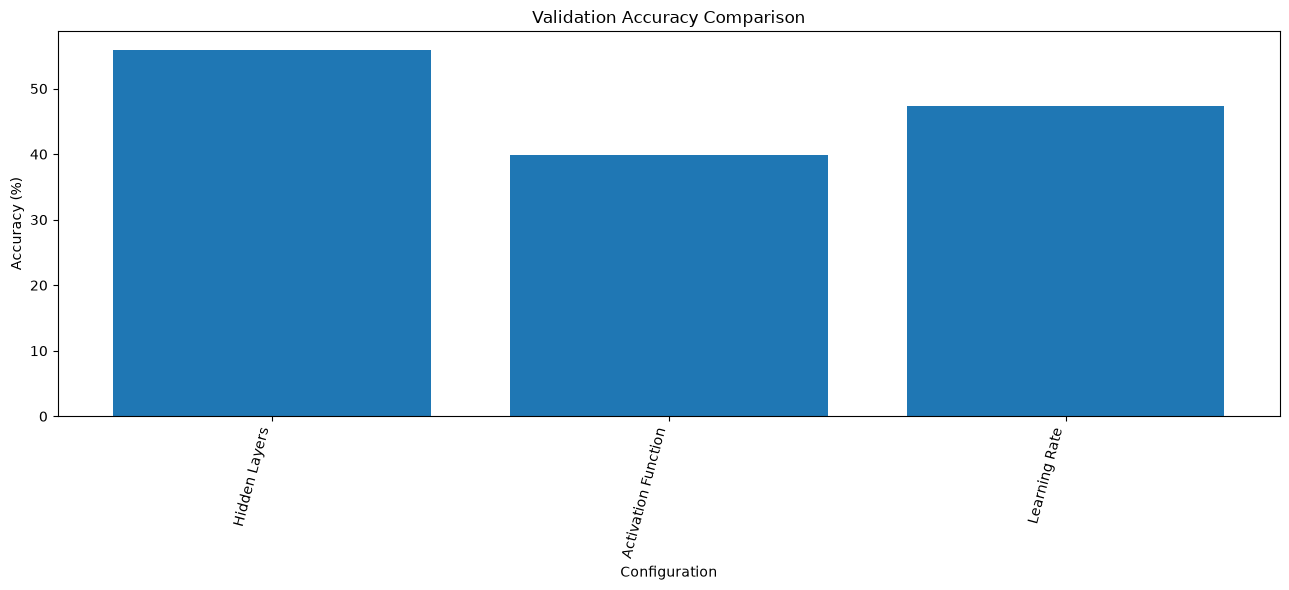

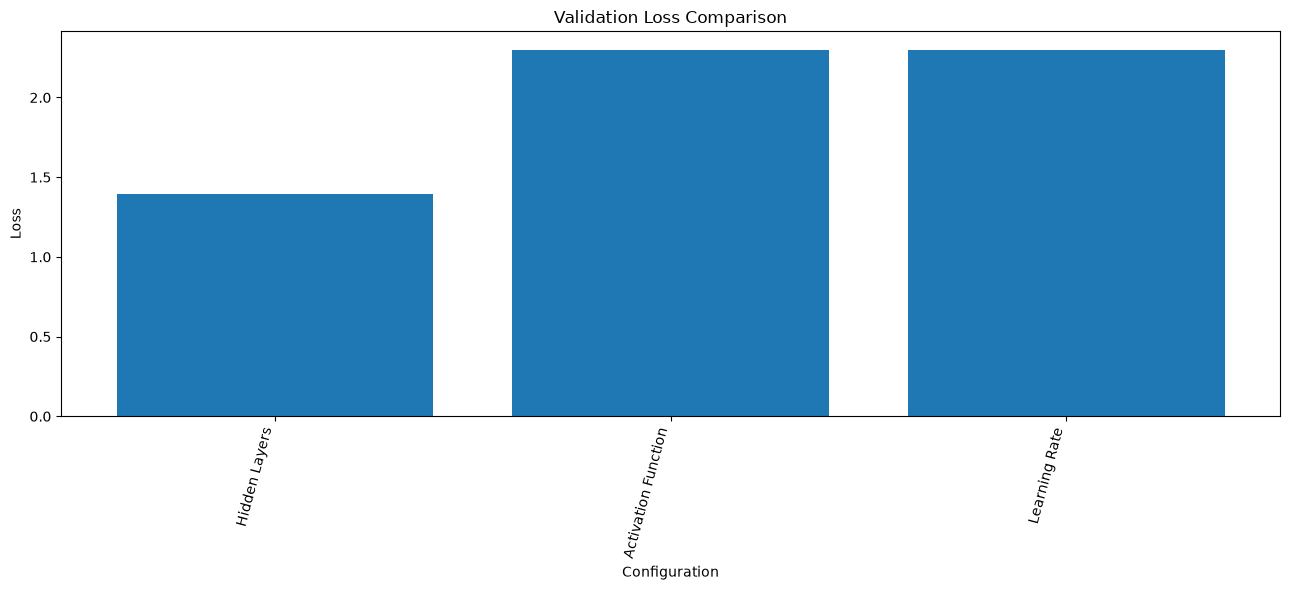

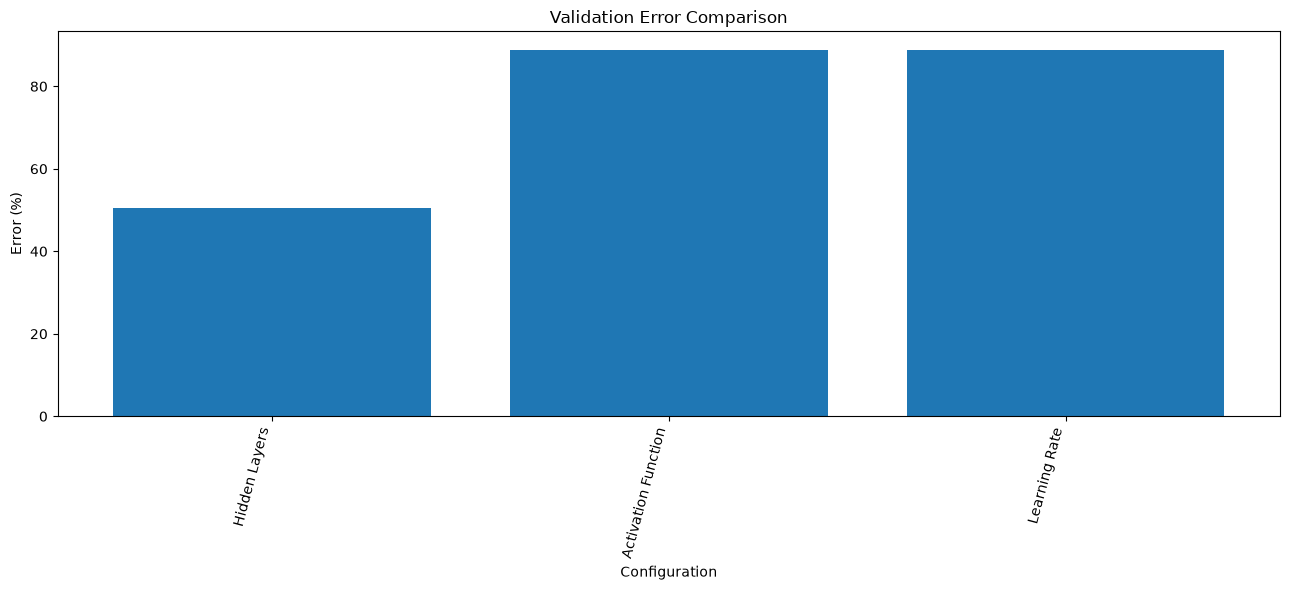

Final comparison plots saved to: C:\Users\jaswa\EuroSAT_ANN_Results\Plots
Sorted comparison table saved to: C:\Users\jaswa\EuroSAT_ANN_Results\Results_Tables


In [41]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = os.path.join(
    tables_dir,
    "all_experiments_validation_comparison.csv"
)
comparison_df = pd.read_csv(comparison_path)

# Identify metric columns from the actual table
print("Columns found:", comparison_df.columns.tolist())

def find_column(df, keywords):
    for col in df.columns:
        name = col.lower().replace("_", " ")
        if all(word in name for word in keywords):
            return col
    return None

loss_col = find_column(comparison_df, ["validation", "loss"])
accuracy_col = find_column(comparison_df, ["validation", "accuracy"])
error_col = find_column(comparison_df, ["validation", "error"])

# Calculate error if not already recorded
if error_col is None and accuracy_col is not None:
    comparison_df["Validation Error (%)"] = (
        100 - comparison_df[accuracy_col]
        if comparison_df[accuracy_col].max() > 1
        else (1 - comparison_df[accuracy_col]) * 100
    )
    error_col = "Validation Error (%)"

# Use configuration labels when available
label_col = next(
    (c for c in ["Configuration", "Model", "Experiment"] if c in comparison_df.columns),
    None
)

if not all([loss_col, accuracy_col, error_col, label_col]):
    print("Could not identify all required columns.")
    print("Loss:", loss_col, "| Accuracy:", accuracy_col,
          "| Error:", error_col, "| Label:", label_col)
else:
    # Keep only valid metric rows
    plot_df = comparison_df.copy()
    for col in [loss_col, accuracy_col, error_col]:
        plot_df[col] = pd.to_numeric(plot_df[col], errors="coerce")

    plot_df = plot_df[
        np.isfinite(plot_df[loss_col]) &
        np.isfinite(plot_df[accuracy_col]) &
        np.isfinite(plot_df[error_col])
    ].copy()

    if plot_df.empty:
        print("No valid metric rows were found.")
    else:
        labels = plot_df[label_col].astype(str)

        for metric, filename, title, ylabel in [
            (accuracy_col, "final_validation_accuracy_comparison.png",
             "Validation Accuracy Comparison", "Accuracy (%)"),
            (loss_col, "final_validation_loss_comparison.png",
             "Validation Loss Comparison", "Loss"),
            (error_col, "final_validation_error_comparison.png",
             "Validation Error Comparison", "Error (%)")
        ]:
            plt.figure(figsize=(13, 6))
            plt.bar(labels, plot_df[metric])
            plt.title(title)
            plt.xlabel("Configuration")
            plt.ylabel(ylabel)
            plt.xticks(rotation=75, ha="right")
            plt.tight_layout()
            plt.savefig(
                os.path.join(plots_dir, filename),
                dpi=300,
                bbox_inches="tight"
            )
            plt.show()

        # Save sorted comparison for reporting
        plot_df.sort_values(loss_col).to_csv(
            os.path.join(tables_dir, "final_validation_comparison_sorted.csv"),
            index=False
        )

        print("Final comparison plots saved to:", plots_dir)
        print("Sorted comparison table saved to:", tables_dir)

In [42]:
import os

for folder in [tables_dir, plots_dir, models_dir, histories_dir]:
    print(f"\n--- {os.path.basename(folder)} ---")

    if os.path.exists(folder):
        files = os.listdir(folder)
        if files:
            for file in files:
                print(file)
        else:
            print("Folder is empty.")
    else:
        print("Folder does not exist.")


--- Results_Tables ---
activation_function_comparison.csv
all_experiments_validation_comparison.csv
final_validation_comparison_sorted.csv
hidden_layer_comparison.csv
learning_rate_comparison.csv

--- Plots ---
final_validation_accuracy_comparison.png
final_validation_error_comparison.png
final_validation_loss_comparison.png

--- Saved_Models ---
Folder is empty.

--- Training_Histories ---
Folder is empty.


In [43]:
print("Baseline model available:", "model" in globals())
print("Best model available:", "best_model" in globals())

print("\nExperiment result variables:")
for name in [
    "hidden_layer_results",
    "activation_results",
    "learning_rate_results"
]:
    print(name, "available:", name in globals())

print("\nSelected model path:")
print(best_model_path if "best_model_path" in globals() else "Not defined")

Baseline model available: True
Best model available: True

Experiment result variables:
hidden_layer_results available: True
activation_results available: True
learning_rate_results available: True

Selected model path:
C:\Users\jaswa\EuroSAT_ANN_Results\Saved_Models\ann_6_hidden_layers.keras


In [44]:
import os
import pandas as pd

# Ensure output folders exist
for folder in [models_dir, histories_dir, tables_dir, plots_dir]:
    os.makedirs(folder, exist_ok=True)

# Save the baseline model
baseline_path = os.path.join(
    models_dir, "baseline_2_hidden_layers.keras"
)
model.save(baseline_path)

# Save the selected best model
best_path = os.path.join(
    models_dir, "best_selected_model.keras"
)
best_model.save(best_path)

# Save baseline training history from memory
baseline_history_df = pd.DataFrame(history.history)
baseline_history_df.index = baseline_history_df.index + 1
baseline_history_df.index.name = "Epoch"

baseline_history_path = os.path.join(
    histories_dir, "baseline_training_history.csv"
)
baseline_history_df.to_csv(baseline_history_path)

print("Baseline model saved:", os.path.exists(baseline_path))
print("Best model saved:", os.path.exists(best_path))
print("Baseline history saved:", os.path.exists(baseline_history_path))

print("\nSaved model files:")
for file in os.listdir(models_dir):
    print(file)

print("\nSaved history files:")
for file in os.listdir(histories_dir):
    print(file)

Baseline model saved: True
Best model saved: True
Baseline history saved: True

Saved model files:
baseline_2_hidden_layers.keras
best_selected_model.keras

Saved history files:
baseline_training_history.csv


In [45]:
print("Number of hidden-layer experiment results:",
      len(hidden_layer_results))

print("\nFirst hidden-layer result:")
print(hidden_layer_results[0])

print("\nNumber of activation experiment results:",
      len(activation_results))

print("\nFirst activation result:")
print(activation_results[0])

print("\nNumber of learning-rate experiment results:",
      len(learning_rate_results))

print("\nFirst learning-rate result:")
print(learning_rate_results[0])

Number of hidden-layer experiment results: 7

First hidden-layer result:
{'Hidden Layers': 2, 'Neurons Per Layer': 64, 'Activation': 'ReLU', 'Learning Rate': 0.001, 'Best Epoch': 10, 'Validation Loss': 1.3943413496017456, 'Validation Accuracy (%)': 49.981480836868286, 'Validation Error (%)': 50.018519163131714}

Number of activation experiment results: 3

First activation result:
{'Activation': 'relu', 'Best Epoch': 10, 'Validation Loss': 1.5723083019256592, 'Validation Accuracy (%)': 39.8888885974884, 'Validation Error (%)': 60.1111114025116}

Number of learning-rate experiment results: 4

First learning-rate result:
{'Learning Rate': 0.1, 'Best Epoch': 1, 'Validation Loss': 2.296741485595703, 'Validation Accuracy (%)': 11.11111119389534, 'Validation Error (%)': 88.88888880610466}


In [46]:
print("HIDDEN-LAYER RESULT TYPE")
print(type(hidden_layer_results[0]))
print(hidden_layer_results[0])

print("\nACTIVATION RESULT TYPE")
print(type(activation_results[0]))
print(activation_results[0])

print("\nLEARNING-RATE RESULT TYPE")
print(type(learning_rate_results[0]))
print(learning_rate_results[0])

HIDDEN-LAYER RESULT TYPE
<class 'dict'>
{'Hidden Layers': 2, 'Neurons Per Layer': 64, 'Activation': 'ReLU', 'Learning Rate': 0.001, 'Best Epoch': 10, 'Validation Loss': 1.3943413496017456, 'Validation Accuracy (%)': 49.981480836868286, 'Validation Error (%)': 50.018519163131714}

ACTIVATION RESULT TYPE
<class 'dict'>
{'Activation': 'relu', 'Best Epoch': 10, 'Validation Loss': 1.5723083019256592, 'Validation Accuracy (%)': 39.8888885974884, 'Validation Error (%)': 60.1111114025116}

LEARNING-RATE RESULT TYPE
<class 'dict'>
{'Learning Rate': 0.1, 'Best Epoch': 1, 'Validation Loss': 2.296741485595703, 'Validation Accuracy (%)': 11.11111119389534, 'Validation Error (%)': 88.88888880610466}


In [47]:
for name, results in [
    ("Hidden Layers", hidden_layer_results),
    ("Activation Functions", activation_results),
    ("Learning Rates", learning_rate_results)
]:
    print(f"\n{name}:")
    print("Number of results:", len(results))
    print("First result type:", type(results[0]).__name__)
    print("First result:", repr(results[0])[:1000])


Hidden Layers:
Number of results: 7
First result type: dict
First result: {'Hidden Layers': 2, 'Neurons Per Layer': 64, 'Activation': 'ReLU', 'Learning Rate': 0.001, 'Best Epoch': 10, 'Validation Loss': 1.3943413496017456, 'Validation Accuracy (%)': 49.981480836868286, 'Validation Error (%)': 50.018519163131714}

Activation Functions:
Number of results: 3
First result type: dict
First result: {'Activation': 'relu', 'Best Epoch': 10, 'Validation Loss': 1.5723083019256592, 'Validation Accuracy (%)': 39.8888885974884, 'Validation Error (%)': 60.1111114025116}

Learning Rates:
Number of results: 4
First result type: dict
First result: {'Learning Rate': 0.1, 'Best Epoch': 1, 'Validation Loss': 2.296741485595703, 'Validation Accuracy (%)': 11.11111119389534, 'Validation Error (%)': 88.88888880610466}


In [48]:
import os
from tensorflow.keras.models import load_model

for filename in [
    "baseline_2_hidden_layers.keras",
    "best_selected_model.keras"
]:
    path = os.path.join(models_dir, filename)

    print(f"\nChecking: {filename}")
    print("File exists:", os.path.isfile(path))

    if os.path.isfile(path):
        try:
            loaded_model = load_model(path)
            print("Model loads successfully.")
            print("Input shape:", loaded_model.input_shape)
            print("Output shape:", loaded_model.output_shape)
        except Exception as e:
            print("Loading error:", repr(e))


Checking: baseline_2_hidden_layers.keras
File exists: True
Model loads successfully.
Input shape: (None, 12288)
Output shape: (None, 10)

Checking: best_selected_model.keras
File exists: True
Model loads successfully.
Input shape: (None, 12288)
Output shape: (None, 10)


In [49]:
import os
import shutil

backup_base = os.path.join(
    os.path.expanduser("~"),
    "EuroSAT_ANN_Results_Backup"
)

zip_path = shutil.make_archive(
    backup_base,
    "zip",
    root_dir=results_dir
)

print("Backup created:", os.path.isfile(zip_path))
print("Backup location:", zip_path)
print("Backup size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))


Backup created: True
Backup location: C:\Users\jaswa\EuroSAT_ANN_Results_Backup.zip
Backup size (MB): 15.85


In [50]:
import os

print("FINAL TEST RESULTS")

for filename in [
    "final_test_metrics.csv",
    "final_test_classification_report.csv",
    "final_test_confusion_matrix.csv",
    "final_test_confusion_matrix.png"
]:
    path = os.path.join(tables_dir, filename)

    # The confusion matrix image is stored in Plots
    if filename.endswith(".png"):
        path = os.path.join(plots_dir, filename)

    print(f"{filename}: {'Saved' if os.path.isfile(path) else 'Missing'}")

FINAL TEST RESULTS
final_test_metrics.csv: Missing
final_test_classification_report.csv: Missing
final_test_confusion_matrix.csv: Missing
final_test_confusion_matrix.png: Missing


85/85 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5519 - loss: 1.2295
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 


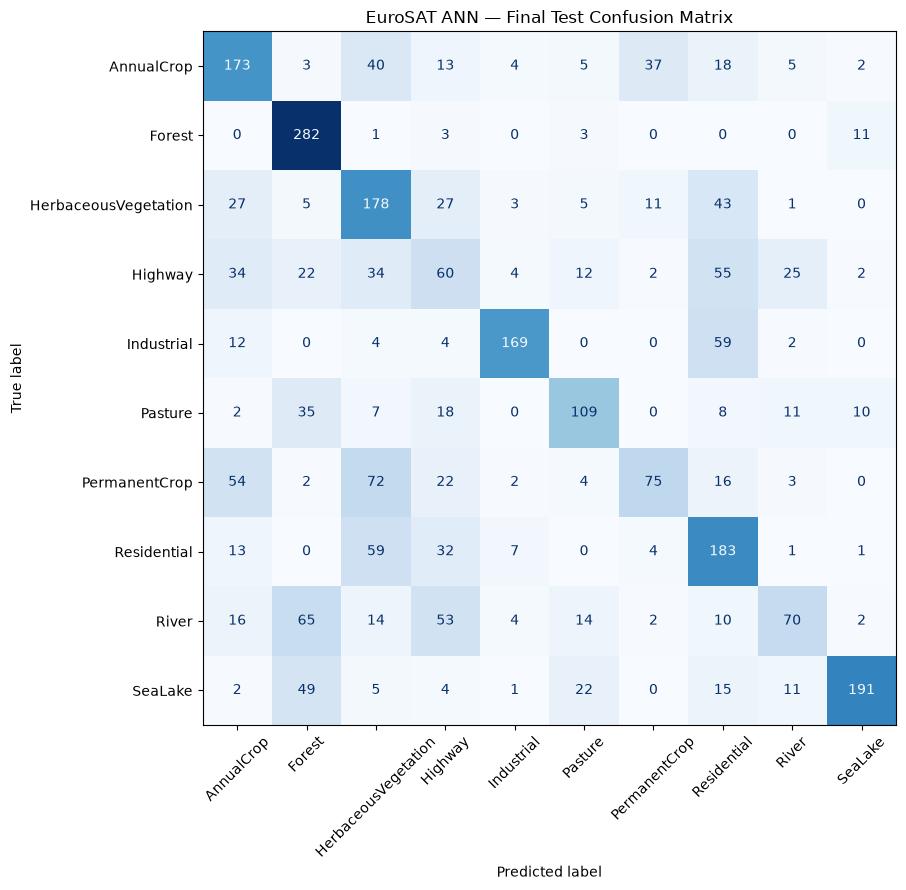


FINAL TEST EVALUATION FILES
final_test_metrics.csv — True
final_test_classification_report.csv — True
final_test_confusion_matrix.csv — True
final_test_confusion_matrix.png — True

Test metrics:


,Selected Configuration,Test Loss,Test Accuracy (%),Test Error (%),Number of Test Images
0,"6 layers, ReLU, LR=0.001",1.229457,55.185187,44.814813,2700



All four files have been recreated from the existing model.


In [51]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

from IPython.display import display as show_table

# Ensure output folders exist
os.makedirs(tables_dir, exist_ok=True)
os.makedirs(plots_dir, exist_ok=True)

# 1. Generate predictions using the existing trained model
test_loss, test_accuracy = best_model.evaluate(
    X_test, y_test, verbose=1
)

y_prob = best_model.predict(
    X_test, batch_size=128, verbose=1
)
y_pred = np.argmax(y_prob, axis=1)

test_error = (1 - test_accuracy) * 100

# 2. Obtain class names in label order
class_names = (
    train_df[["Label", "ClassName"]]
    .drop_duplicates()
    .sort_values("Label")["ClassName"]
    .tolist()
)

# 3. Save final test metrics
test_metrics_df = pd.DataFrame([{
    "Selected Configuration": (
        best_result["Configuration"]
        if "best_result" in globals()
        and "Configuration" in best_result.index
        else "Selected ANN model"
    ),
    "Test Loss": test_loss,
    "Test Accuracy (%)": test_accuracy * 100,
    "Test Error (%)": test_error,
    "Number of Test Images": len(y_test)
}])

test_metrics_path = os.path.join(
    tables_dir, "final_test_metrics.csv"
)
test_metrics_df.to_csv(test_metrics_path, index=False)

# 4. Save classification report
report_dict = classification_report(
    y_test,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).transpose()

report_path = os.path.join(
    tables_dir, "final_test_classification_report.csv"
)
report_df.to_csv(report_path)

# 5. Save confusion matrix as CSV
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=list(range(len(class_names)))
)

cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)
cm_df.index.name = "Actual Class"

cm_path = os.path.join(
    tables_dir, "final_test_confusion_matrix.csv"
)
cm_df.to_csv(cm_path)

# 6. Save confusion matrix as an image
fig, ax = plt.subplots(figsize=(11, 9))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=45,
    cmap="Blues",
    colorbar=False
)

ax.set_title("EuroSAT ANN — Final Test Confusion Matrix")
fig.tight_layout()

cm_plot_path = os.path.join(
    plots_dir, "final_test_confusion_matrix.png"
)
fig.savefig(cm_plot_path, dpi=300, bbox_inches="tight")
plt.show()
plt.close(fig)

# 7. Confirm saved files
print("\nFINAL TEST EVALUATION FILES")
for path in [
    test_metrics_path,
    report_path,
    cm_path,
    cm_plot_path
]:
    print(os.path.basename(path), "—", os.path.isfile(path))

print("\nTest metrics:")
show_table(test_metrics_df)

print("\nAll four files have been recreated from the existing model.")

In [52]:
import os
import shutil

# Verify all expected outputs
expected_files = {
    "Results_Tables": [
        "hidden_layer_comparison.csv",
        "activation_function_comparison.csv",
        "learning_rate_comparison.csv",
        "all_experiments_validation_comparison.csv",
        "final_test_metrics.csv",
        "final_test_classification_report.csv",
        "final_test_confusion_matrix.csv"
    ],
    "Plots": [
        "final_validation_accuracy_comparison.png",
        "final_validation_loss_comparison.png",
        "final_validation_error_comparison.png",
        "final_test_confusion_matrix.png"
    ],
    "Saved_Models": [
        "baseline_2_hidden_layers.keras",
        "best_selected_model.keras"
    ]
}

all_present = True

for folder_name, filenames in expected_files.items():
    folder_path = os.path.join(results_dir, folder_name)
    print(f"\n--- {folder_name} ---")

    for filename in filenames:
        exists = os.path.isfile(os.path.join(folder_path, filename))
        print(f"{'OK' if exists else 'MISSING'}: {filename}")
        if not exists:
            all_present = False

# Update the ZIP backup
backup_base = os.path.join(
    os.path.expanduser("~"),
    "EuroSAT_ANN_Results_Backup"
)
zip_path = shutil.make_archive(
    backup_base,
    "zip",
    root_dir=results_dir
)

print("\nAll expected files present:", all_present)
print("Updated backup:", zip_path)
print("Backup size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))


--- Results_Tables ---
OK: hidden_layer_comparison.csv
OK: activation_function_comparison.csv
OK: learning_rate_comparison.csv
OK: all_experiments_validation_comparison.csv
OK: final_test_metrics.csv
OK: final_test_classification_report.csv
OK: final_test_confusion_matrix.csv

--- Plots ---
OK: final_validation_accuracy_comparison.png
OK: final_validation_loss_comparison.png
OK: final_validation_error_comparison.png
OK: final_test_confusion_matrix.png

--- Saved_Models ---
OK: baseline_2_hidden_layers.keras
OK: best_selected_model.keras

All expected files present: True
Updated backup: C:\Users\jaswa\EuroSAT_ANN_Results_Backup.zip
Backup size (MB): 16.1


In [5]:
import os

results_dir = os.path.join(
    os.getcwd(),
    "EuroSAT_ANN_Results"
)

print("Folder exists:", os.path.exists(results_dir))

if os.path.exists(results_dir):
    print("Contents:", os.listdir(results_dir))

Folder exists: True
Contents: ['Plots', 'Results_Tables', 'Saved_Models', 'Training_Histories']


In [6]:
import shutil
from IPython.display import FileLink, display

zip_path = shutil.make_archive(
    os.path.join(os.getcwd(), "EuroSAT_ANN_Results_Backup"),
    "zip",
    root_dir=os.getcwd(),
    base_dir="EuroSAT_ANN_Results"
)

display(FileLink(zip_path))

C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results_Backup.zip

In [7]:
import os

for root, dirs, files in os.walk(results_dir):
    for file in files:
        if file.endswith(".csv"):
            print(os.path.relpath(os.path.join(root, file), results_dir))

Results_Tables\activation_function_comparison.csv
Results_Tables\all_experiments_validation_comparison.csv
Results_Tables\final_test_classification_report.csv
Results_Tables\final_test_confusion_matrix.csv
Results_Tables\final_test_metrics.csv
Results_Tables\hidden_layer_comparison.csv
Results_Tables\learning_rate_comparison.csv
Training_Histories\activation_relu_history.csv
Training_Histories\activation_sigmoid_history.csv
Training_Histories\activation_tanh_history.csv
Training_Histories\ann_2_hidden_layers_history.csv
Training_Histories\ann_3_hidden_layers_history.csv
Training_Histories\ann_4_hidden_layers_history.csv
Training_Histories\ann_5_hidden_layers_history.csv
Training_Histories\ann_6_hidden_layers_history.csv
Training_Histories\ann_7_hidden_layers_history.csv
Training_Histories\ann_8_hidden_layers_history.csv
Training_Histories\baseline_training_history.csv
Training_Histories\learning_rate_0p0001_history.csv
Training_Histories\learning_rate_0p001_history.csv
Training_Histori

In [8]:
import os
import pandas as pd

results_dir = os.path.join(
    os.getcwd(),
    "EuroSAT_ANN_Results"
)

tables_dir = os.path.join(results_dir, "Results_Tables")

for file in os.listdir(tables_dir):
    if file.endswith(".csv"):
        df = pd.read_csv(os.path.join(tables_dir, file))
        print("\nFILE:", file)
        print("Shape:", df.shape)
        print("Columns:", list(df.columns))


FILE: activation_function_comparison.csv
Shape: (3, 5)
Columns: ['Activation', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)']

FILE: all_experiments_validation_comparison.csv
Shape: (15, 7)
Columns: ['Experiment', 'Configuration', 'Best Epoch', 'Validation Loss', 'Validation Accuracy (%)', 'Validation Error (%)', 'Model File']

FILE: final_test_classification_report.csv
Shape: (13, 5)
Columns: ['Unnamed: 0', 'precision', 'recall', 'f1-score', 'support']

FILE: final_test_confusion_matrix.csv
Shape: (10, 11)
Columns: ['Actual Class', 'AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']

FILE: final_test_metrics.csv
Shape: (1, 5)
Columns: ['Selected Configuration', 'Test Loss', 'Test Accuracy (%)', 'Test Error (%)', 'Number of Test Images']

FILE: hidden_layer_comparison.csv
Shape: (7, 8)
Columns: ['Hidden Layers', 'Neurons Per Layer', 'Activation', 'Learning Rate', 'B

In [9]:
import pandas as pd
import os

report_path = os.path.join(
    tables_dir,
    "final_test_classification_report.csv"
)

report_df = pd.read_csv(report_path)

display(report_df)

,Unnamed: 0,precision,recall,f1-score,support
0,AnnualCrop,0.519520,0.576667,0.546603,300.000000
1,Forest,0.609071,0.940000,0.739187,300.000000
2,HerbaceousVegetation,0.429952,0.593333,0.498599,300.000000
3,Highway,0.254237,0.240000,0.246914,250.000000
4,Industrial,0.871134,0.676000,0.761261,250.000000
5,Pasture,0.626437,0.545000,0.582888,200.000000
6,PermanentCrop,0.572519,0.300000,0.393701,250.000000
7,Residential,0.449631,0.610000,0.517680,300.000000
8,River,0.542636,0.280000,0.369393,250.000000
9,SeaLake,0.872146,0.636667,0.736031,300.000000


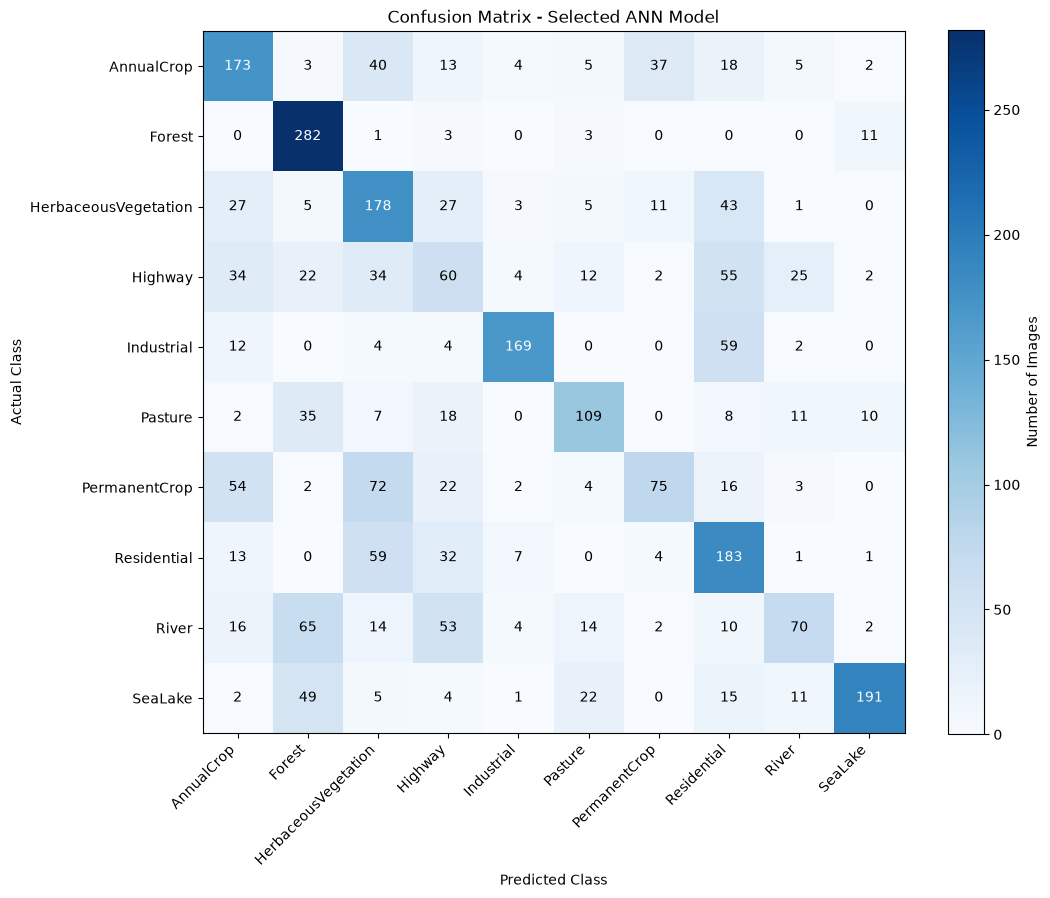

Confusion matrix saved: C:\Users\jaswa\EuroSAT_ANN_Results\Plots\final_test_confusion_matrix.png


In [10]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import os

# Read existing confusion matrix
cm_path = os.path.join(
    tables_dir,
    "final_test_confusion_matrix.csv"
)

cm_df = pd.read_csv(cm_path)

# Extract numerical confusion matrix
class_names = cm_df["Actual Class"].tolist()
cm = cm_df[class_names].values

# Create heatmap
plt.figure(figsize=(11, 9))

plt.imshow(cm, interpolation="nearest", cmap="Blues")
plt.title("Confusion Matrix - Selected ANN Model")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")

plt.xticks(range(len(class_names)), class_names, rotation=45, ha="right")
plt.yticks(range(len(class_names)), class_names)

# Display values inside each cell
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center",
            va="center",
            color="white" if cm[i, j] > cm.max() / 2 else "black"
        )

plt.colorbar(label="Number of Images")
plt.tight_layout()

# Save image
confusion_plot_path = os.path.join(
    plots_dir,
    "final_test_confusion_matrix.png"
)

plt.savefig(
    confusion_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Confusion matrix saved:", confusion_plot_path)

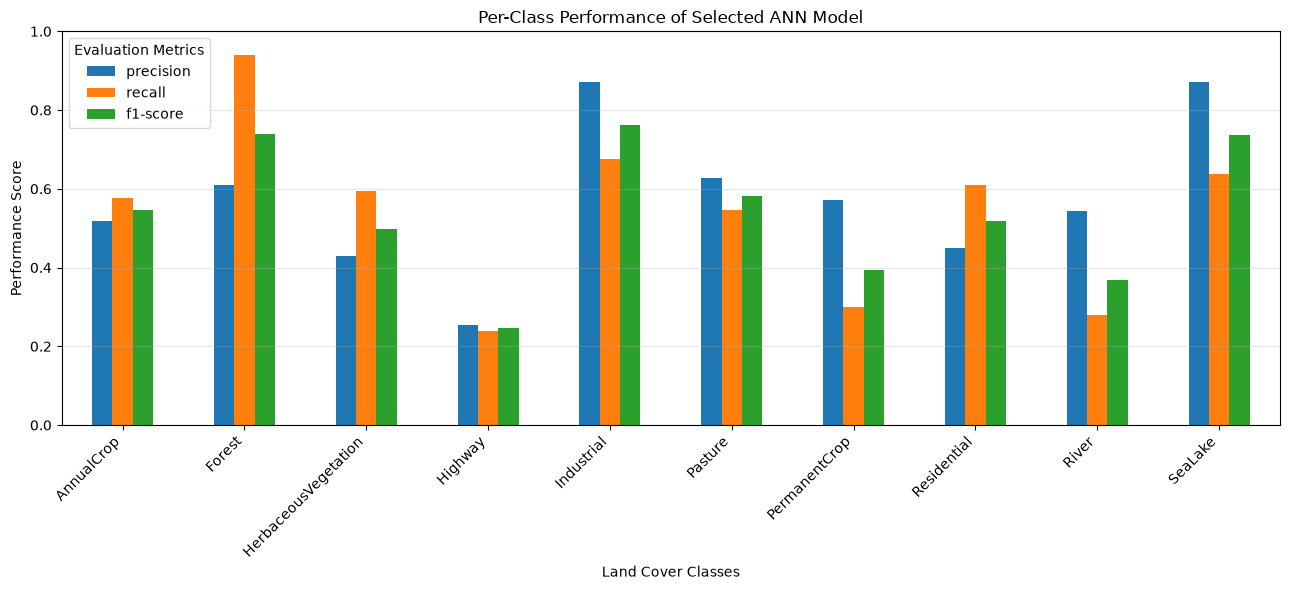

Saved successfully: C:\Users\jaswa\EuroSAT_ANN_Results\Plots\per_class_performance.png


In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Read classification report
report_path = os.path.join(
    tables_dir,
    "final_test_classification_report.csv"
)

report_df = pd.read_csv(report_path)

# Select the 10 land-cover classes
class_df = report_df.iloc[:10].copy()

class_names = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River", "SeaLake"
]

class_df["Class"] = class_names

# Create comparison chart
ax = class_df.plot(
    x="Class",
    y=["precision", "recall", "f1-score"],
    kind="bar",
    figsize=(13, 6)
)

plt.title("Per-Class Performance of Selected ANN Model")
plt.xlabel("Land Cover Classes")
plt.ylabel("Performance Score")
plt.ylim(0, 1)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

# Save plot
plot_path = os.path.join(
    plots_dir,
    "per_class_performance.png"
)

plt.savefig(plot_path, dpi=300, bbox_inches="tight")
plt.show()

print("Saved successfully:", plot_path)

In [13]:
import os
from tensorflow.keras.models import load_model

models_dir = os.path.join(
    os.getcwd(),
    "EuroSAT_ANN_Results",
    "Saved_Models"
)

model_path = os.path.join(
    models_dir,
    "best_selected_model.keras"
)

best_model = load_model(model_path)

print("Best ANN model loaded successfully!")
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

ValueError: File not found: filepath=C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\best_selected_model.keras. Please ensure the file is an accessible `.keras` zip file.

In [14]:
import os

search_dir = os.getcwd()

print("Searching from:", search_dir)

for root, dirs, files in os.walk(search_dir):
    for file in files:
        if file.endswith(".keras"):
            print("FOUND:", os.path.join(root, file))

Searching from: C:\Users\jaswa\AI_ML\Assignment_05
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_relu.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_sigmoid.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_tanh.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_2_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_3_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_4_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_5_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_6_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_7_hidden_layers.keras
FOUND: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT

In [15]:
import os

for root, dirs, files in os.walk(os.path.expanduser("~")):
    for file in files:
        if file.endswith(".keras"):
            print(os.path.join(root, file))

C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_relu.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_sigmoid.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\activation_tanh.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_2_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_3_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_4_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_5_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_6_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_7_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\ann_8_hidden_layers.keras
C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Saved_Models\b

In [16]:
from tensorflow.keras.models import load_model

model_path = r"C:\Users\jaswa\EuroSAT_ANN_Results\Saved_Models\best_selected_model.keras"

best_model = load_model(model_path)

print("Best ANN model loaded successfully!")
print("Input shape:", best_model.input_shape)
print("Output shape:", best_model.output_shape)

Best ANN model loaded successfully!
Input shape: (None, 12288)
Output shape: (None, 10)


In [17]:
print("X_test available:", "X_test" in globals())
print("y_test available:", "y_test" in globals())

if "X_test" in globals():
    print("X_test shape:", X_test.shape)

if "y_test" in globals():
    print("y_test shape:", y_test.shape)

X_test available: False
y_test available: False


In [18]:
print("test_df available:", "test_df" in globals())
print("load_eurosat_images available:", "load_eurosat_images" in globals())
print("rgb_path available:", "rgb_path" in globals())

test_df available: False
load_eurosat_images available: False
rgb_path available: False


In [19]:
import os

print("Dataset cache folders:")
print(os.path.expanduser("~/.cache/kagglehub"))

Dataset cache folders:
C:\Users\jaswa/.cache/kagglehub


In [20]:
import os

cache_path = os.path.expanduser("~/.cache/kagglehub")

for root, dirs, files in os.walk(cache_path):
    if "test.csv" in files:
        print("Dataset folder:", root)
        print("Files:", files)

Dataset folder: C:\Users\jaswa/.cache/kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT
Files: ['label_map.json', 'test.csv', 'train.csv', 'validation.csv']
Dataset folder: C:\Users\jaswa/.cache/kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSATallBands
Files: ['label_map.json', 'test.csv', 'train.csv', 'validation.csv']


In [21]:
import os
import pandas as pd

dataset_path = r"C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT"

test_df = pd.read_csv(os.path.join(dataset_path, "test.csv"))

print("Test dataset shape:", test_df.shape)
print("Column names:", test_df.columns.tolist())
print(test_df.head())

Test dataset shape: (2700, 4)
Column names: ['Unnamed: 0', 'Filename', 'Label', 'ClassName']
   Unnamed: 0                          Filename  Label    ClassName
0        2438    AnnualCrop/AnnualCrop_1275.jpg      0   AnnualCrop
1        1018   Residential/Residential_504.jpg      7  Residential
2           3           Pasture/Pasture_787.jpg      5      Pasture
3        1011  Residential/Residential_1575.jpg      7  Residential
4          47           Pasture/Pasture_473.jpg      5      Pasture


In [22]:
import os

image_folder = os.path.join(dataset_path, "EuroSAT")

print("Image folder exists:", os.path.exists(image_folder))
print("Sample image exists:", os.path.exists(
    os.path.join(image_folder, test_df.iloc[0]["Filename"])
))
print("Sample image path:", os.path.join(
    image_folder, test_df.iloc[0]["Filename"]
))

Image folder exists: False
Sample image exists: False
Sample image path: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT\EuroSAT\AnnualCrop/AnnualCrop_1275.jpg


In [23]:
import os

base_path = r"C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6"

target_file = "AnnualCrop_1275.jpg"

for root, dirs, files in os.walk(base_path):
    if target_file in files:
        print("Correct image location:", os.path.join(root, target_file))

Correct image location: C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT\AnnualCrop\AnnualCrop_1275.jpg


In [24]:
image_folder = r"C:\Users\jaswa\.cache\kagglehub\datasets\apollo2506\eurosat-dataset\versions\6\EuroSAT"

In [25]:
import os

missing_images = []

for filename in test_df["Filename"]:
    image_path = os.path.join(image_folder, filename)
    if not os.path.exists(image_path):
        missing_images.append(filename)

print("Total test images:", len(test_df))
print("Missing images:", len(missing_images))
print("Available images:", len(test_df) - len(missing_images))

Total test images: 2700
Missing images: 0
Available images: 2700


In [26]:
import numpy as np
from PIL import Image
from tqdm import tqdm
import os

X_test = []

for filename in tqdm(test_df["Filename"]):
    image_path = os.path.join(image_folder, filename)

    img = Image.open(image_path).convert("RGB")
    img = img.resize((64, 64))

    X_test.append(np.asarray(img, dtype=np.float32).flatten())

X_test = np.array(X_test)

y_test = test_df["Label"].to_numpy()

print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

100%|██████████| 2700/2700 [00:02<00:00, 970.65it/s] 

X_test shape: (2700, 12288)
y_test shape: (2700,)


In [27]:
print("Minimum pixel value:", X_test.min())
print("Maximum pixel value:", X_test.max())
print("Data type:", X_test.dtype)

Minimum pixel value: 15.0
Maximum pixel value: 255.0
Data type: float32


In [28]:
best_model.summary()

Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_21 (Dense)                     │ (None, 64)                  │         786,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_22 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_23 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_24 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_25 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_26 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_27 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,423,840 (9.25 MB)

 Trainable params: 807,946 (3.08 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,615,894 (6.16 MB)

In [29]:
from sklearn.metrics import accuracy_score
import numpy as np

# Prediction using raw pixel values
pred_raw = np.argmax(best_model.predict(X_test, verbose=0), axis=1)
accuracy_raw = accuracy_score(y_test, pred_raw) * 100

# Prediction using normalized pixel values
pred_normalized = np.argmax(
    best_model.predict(X_test / 255.0, verbose=0), axis=1
)
accuracy_normalized = accuracy_score(y_test, pred_normalized) * 100

print("Accuracy with raw pixels:", round(accuracy_raw, 2), "%")
print("Accuracy with normalized pixels:", round(accuracy_normalized, 2), "%")

Accuracy with raw pixels: 22.59 %
Accuracy with normalized pixels: 55.19 %


In [30]:
import numpy as np
import pandas as pd
import os

class_names = [
    "AnnualCrop", "Forest", "HerbaceousVegetation",
    "Highway", "Industrial", "Pasture",
    "PermanentCrop", "Residential", "River", "SeaLake"
]

X_test_normalized = X_test / 255.0

y_pred_prob = best_model.predict(X_test_normalized, verbose=0)
y_pred = np.argmax(y_pred_prob, axis=1)

prediction_df = pd.DataFrame({
    "Image_Index": range(len(y_test)),
    "Actual_Class": [class_names[i] for i in y_test],
    "Predicted_Class": [class_names[i] for i in y_pred],
    "Correct_Prediction": y_test == y_pred,
    "Prediction_Confidence": np.max(y_pred_prob, axis=1)
})

prediction_path = os.path.join(tables_dir, "actual_vs_predicted.csv")
prediction_df.to_csv(prediction_path, index=False)

print("CSV saved successfully!")
print("File:", prediction_path)
print(prediction_df.head())

CSV saved successfully!
File: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results\Results_Tables\actual_vs_predicted.csv
   Image_Index Actual_Class       Predicted_Class  Correct_Prediction  \
0            0   AnnualCrop  HerbaceousVegetation               False   
1            1  Residential                 River               False   
2            2      Pasture               Pasture                True   
3            3  Residential           Residential                True   
4            4      Pasture               Pasture                True   

   Prediction_Confidence  
0               0.259294  
1               0.371415  
2               0.414655  
3               0.494027  
4               0.798241  


In [31]:
import os

results_dir = os.path.join(os.getcwd(), "EuroSAT_ANN_Results")

print("Project folder:", results_dir)
print("\nSubfolders:")

for item in os.listdir(results_dir):
    path = os.path.join(results_dir, item)
    if os.path.isdir(path):
        print(item, " - ", len(os.listdir(path)), "items")

Project folder: C:\Users\jaswa\AI_ML\Assignment_05\EuroSAT_ANN_Results

Subfolders:
Plots  -  24 items
Results_Tables  -  8 items
Saved_Models  -  15 items
Training_Histories  -  15 items
